# Taller de IA · El problema del viajante (TSP)
## A* con MST · Hill Climbing vs. Simulated Annealing · Algoritmo genético · RBFS

**Versión completada y ejecutada — implementaciones propias, pruebas, figuras, resultados y análisis.**

**Duración propuesta:** dos sesiones. **Modalidad:** parejas / individual. **Entrega:** este mismo cuaderno, completado con las implementaciones propias, pruebas, figuras, resultados y análisis.

**Pregunta central:** ¿qué se gana y qué se pierde al cambiar garantía de optimalidad por rapidez, diversidad o menor consumo de memoria?

Instancias obligatorias: **att48, berlin52, brazil58 y gr48**. Se trabajará también con subinstancias pequeñas para verificar los métodos exactos. Instancias de ampliación: gr17, burma14 y eil51.



## 1. Punto de partida y lectura crítica

La página [TSP Solve](https://sites.google.com/view/tsp-solve/homepage) presenta A*, Hill Climbing y RBFS en MATLAB. Este taller amplía el alcance con recocido simulado y un algoritmo genético. Los procedimientos que siguen son una formulación didáctica propia; no constituyen una traducción del código MATLAB.

Antes de programar, revise estas dos diferencias:

1. Intercambiar las posiciones de dos ciudades es **swap**. El movimiento **2-opt** elimina dos aristas y reconecta el ciclo invirtiendo un segmento. No son movimientos equivalentes en general.
2. En TSP, llegar a la misma ciudad por rutas parciales diferentes no significa llegar al mismo estado: importa también el conjunto de ciudades pendientes. Las reglas de descarte deben respetar esta información.

La página reporta resultados no óptimos para algunas ejecuciones de su variante denominada A* de grafo. Eso motiva una auditoría de estados y reglas de descarte; no demuestra que A* correctamente formulado pierda su garantía de optimalidad.

**Actividad de lectura:** identifique qué código del sitio realiza swap y explique qué debería cambiar para implementar 2-opt. Examine qué información necesita la clave de un estado de A*. No use los tiempos publicados como objetivos de rendimiento de su implementación.



## 2. Objetivos y reglas del trabajo

Al finalizar, deberá poder:

- Modelar el TSP como búsqueda de rutas parciales y como optimización de permutaciones completas.
- Construir y justificar una heurística basada en árbol de expansión mínima (MST).
- Implementar A*, RBFS, Hill Climbing, Simulated Annealing y un algoritmo genético con operadores válidos para permutaciones.
- Diseñar experimentos reproducibles y distinguir solución válida, mejor solución observada y optimalidad demostrada.
- Interpretar convergencia, brecha al óptimo, memoria y costo computacional.

**Implementación:** escriba los cinco algoritmos desde cero. Puede usar herramientas para arreglos, gráficas, tablas, lectura de archivos y medición. Se permite `tsplib95` para cargar datos y obtener pesos oficiales. Implemente el MST mediante Prim o Kruskal; no delegue las búsquedas ni la optimización a un solver, SimpleAI, DEAP o una biblioteca equivalente en la comparación principal.

Los nombres sugeridos de componentes e identificadores están en inglés; las explicaciones y conclusiones se entregan en español. Toda ayuda externa deberá declararse. Cada integrante debe poder explicar y modificar su implementación durante la sustentación.



## 3. Banco de problemas TSPLIB

| Instancia | Ciudades | Tipo de pesos | Óptimo oficial del ciclo | Papel en el taller |
|---|---:|---|---:|---|
| att48 | 48 | ATT: distancia pseudoeuclidiana | 10628 | Detectar errores de distancia y redondeo |
| berlin52 | 52 | EUC_2D: distancia euclidiana entera | 7542 | Relacionar rutas con una representación geométrica |
| brazil58 | 58 | EXPLICIT: pesos de una matriz | 25395 | Separar optimización de coordenadas |
| gr48 | 48 | EXPLICIT: pesos de una matriz | 5046 | Comparar dos problemas del mismo tamaño y estructura diferente |
| gr17 · ampliación | 17 | EXPLICIT | 2085 | Exploración exacta intermedia, bajo límites |
| burma14 · ampliación | 14 | GEO | 3323 | Estudiar un tipo de distancia adicional |
| eil51 · ampliación | 51 | EUC_2D | 426 | Generalización de métodos aproximados |

Fuentes: [documentación TSPLIB](https://comopt.ifi.uni-heidelberg.de/software/TSPLIB95/tsp95.pdf), [óptimos oficiales](https://comopt.ifi.uni-heidelberg.de/software/TSPLIB95/tsp/TSP-BEST.html) y [repositorio oficial de archivos](https://comopt.ifi.uni-heidelberg.de/software/TSPLIB95/tsp/tspindex.html).



### 3.1. Preparación y auditoría de los datos

Lea `NAME`, `TYPE`, `DIMENSION`, `EDGE_WEIGHT_TYPE` y, cuando exista, `EDGE_WEIGHT_FORMAT`. Reconstruya una matriz simétrica de costos `D`. No presuponga que la numeración de nodos coincide con las posiciones de una lista: conserve una correspondencia explícita entre identificadores y posiciones.

Se recomienda obtener cada peso mediante la interfaz de `tsplib95`, que distingue pesos explícitos y funciones de distancia. La biblioteca no incluye las instancias. Consulte su [documentación de uso](https://tsplib95.readthedocs.io/en/stable/pages/usage.html).

```text
PROCEDURE LoadInstance(file)
    problem ← leer archivo TSPLIB descomprimido
    nodeIds ← lista ordenada de identificadores reales
    PARA cada par de posiciones i, j
        D[i,j] ← peso oficial entre nodeIds[i] y nodeIds[j]
    verificar dimensión, simetría, diagonal cero y pesos no negativos
    devolver metadatos, nodeIds, D y datos de dibujo disponibles
```

**Entregue:** una ficha por instancia, tres pesos calculados o consultados manualmente y una comprobación automática independiente del costo de una ruta. Si usa un archivo `.opt.tour` oficial disponible, verifique su validez y costo; no lo use como población inicial ni como ruta inicial.



In [1]:
!pip install -q tsplib95


### 3.2. Dos reglas de distancia que deben comprender

Para berlin52 (EUC_2D), con $r=\sqrt{(x_i-x_j)^2+(y_i-y_j)^2}$:

$$d(i,j)=\lfloor r+0.5\rfloor.$$

Para att48 (ATT):

$$r=\sqrt{\frac{(x_i-x_j)^2+(y_i-y_j)^2}{10}},\qquad t=\lfloor r+0.5\rfloor,$$

$$d(i,j)=\begin{cases}t+1&\text{si }t<r,\\t&\text{en otro caso.}\end{cases}$$

Para brazil58 y gr48 se utilizan los pesos del archivo, respetando su formato matricial. No reemplace esos pesos por distancias euclidianas. Estas reglas corresponden a la especificación TSPLIB; no aplique el redondeo de empates de un lenguaje sin comprobarlo.



## 4. Modelo común y arquitectura de su solución

Sea $V$ el conjunto de ciudades y $s$ una ciudad inicial fija. Una ruta completa es una permutación $\pi=(s,\pi_1,\ldots,\pi_{n-1})$. El origen no se repite en la representación; el costo incluye el regreso:

$$C(\pi)=\sum_{i=0}^{n-2}d(\pi_i,\pi_{i+1})+d(\pi_{n-1},s).$$

| Componente sugerido | Responsabilidad | Evidencia exigida |
|---|---|---|
| `TSPInstance` | Pesos, metadatos e identificadores | Fichas y auditoría |
| `Tour` | Permutación, validez y costo | Casos de cierre y duplicados |
| `SearchNode` | Estado parcial, costo y reconstrucción | Traza de búsqueda |
| `MSTHeuristic` | MST y conexiones de extremos | Justificación y casos frontera |
| `AStarSolver`, `RBFSSolver` | Búsqueda de rutas parciales | Pruebas exactas pequeñas |
| `HillClimbingSolver`, `AnnealingSolver`, `GeneticSolver` | Optimización de rutas completas | Curvas y repeticiones |
| `ExperimentRunner`, `RunResult` | Presupuestos, semillas y medición | Tablas reproducibles |



## 5. Rutas parciales para A* y RBFS

Un nodo conserva `last`, `remaining`, `g`, `parent` y `closed`. `g` mide solamente aristas ya recorridas. `closed` distingue el regreso final al origen.

- Raíz: `last = s`, `remaining = V − {s}`, `g = 0`, `closed = false`.
- Extensión: ir desde `last` a una ciudad pendiente y eliminarla de `remaining`.
- Si no quedan pendientes, generar un único sucesor que regresa a `s`, añade ese costo y marca `closed = true`.
- Meta: `closed = true`. Una ruta que ya visitó todas las ciudades pero aún no regresó no es meta.

**Clave de estado:** `(last, remaining, closed)`, con el mismo origen fijo. Dos nodos con esta clave comparten las mismas continuaciones; puede conservarse el de menor `g`. La ciudad, la profundidad o la cantidad de pendientes por sí solas no identifican el estado.



## 6. Heurística MST: definición y demostración

Para una ciudad actual $v$ y pendientes $U$:

$$h(v,U)=\begin{cases}
0&\text{si el ciclo está cerrado},\\
d(v,s)&\text{si }U=\varnothing\text{ y falta cerrar},\\
\operatorname{MST}(U)+\min_{u\in U}d(v,u)+\min_{u\in U}d(u,s)&\text{en otro caso.}
\end{cases}$$

Se define $\operatorname{MST}(\varnothing)=\operatorname{MST}(\{u\})=0$. Para un solo pendiente la fórmula calcula exactamente el costo restante. En la raíz, las dos conexiones mínimas pueden seleccionar la misma ciudad; es una relajación válida aunque dé una cota menos ajustada.

**Idea de admisibilidad:** toda continuación conecta la ciudad actual con el primer pendiente, recorre todos los pendientes y termina conectando el último con el origen. Las aristas internas forman un camino que abarca $U$, cuyo costo es al menos el del MST. Cada arista de conexión cuesta al menos el mínimo correspondiente. La suma no sobreestima el costo restante. No se necesita desigualdad triangular para esta justificación en el TSP simétrico de pesos no negativos.



### 6.1. Pseudocódigo de Prim y de la cota

```text
PROCEDURE MSTCost(U)
    SI |U| ≤ 1: devolver 0
    connected ← {una ciudad de U}; total ← 0
    MIENTRAS connected ≠ U
        (a,b) ← arista de menor peso con a en connected y b en U − connected
        total ← total + D[a,b]
        añadir b a connected
    devolver total

PROCEDURE Heuristic(node)
    SI node.closed: devolver 0
    U ← node.remaining
    SI U está vacío: devolver D[node.last,s]
    devolver MSTCost(U) + mínimo D[node.last,u] para u en U
                       + mínimo D[u,s] para u en U
```



### 6.2. Microcaso manual: primero comprender, luego programar

Use esta matriz simétrica de cinco ciudades:

| D | A | B | C | D | E |
|---|---:|---:|---:|---:|---:|
| A | 0 | 4 | 6 | 7 | 3 |
| B | 4 | 0 | 2 | 5 | 6 |
| C | 6 | 2 | 0 | 3 | 4 |
| D | 7 | 5 | 3 | 0 | 2 |
| E | 3 | 6 | 4 | 2 | 0 |

Para el prefijo A → B: $g=4$, $U=\{C,D,E\}$, MST de costo $5$, conexión B → U de costo $2$ y U → A de costo $3$. Así, $h=10$ y $f=g+h=14$.



## 7. A* con MST y control de estados repetidos

Priorice por $f=g+h$. Use una cola de prioridad y un desempate estable. La ruta se reconstruye mediante nodos o registros inmutables de padres.

```text
PROCEDURE AStar(root, budget)
    root.f ← root.g + Heuristic(root)
    open ← cola de prioridad que contiene root
    bestG[Key(root)] ← root.g
    MIENTRAS open no esté vacía
        SI se alcanzó budget: devolver INTERRUPTED, sin certificado
        node ← extraer mínimo f de open
        SI node.g > bestG[Key(node)]: continuar
        SI node.closed: devolver ruta reconstruida, OPTIMAL
        registrar expansión de node
        PARA cada child en Successors(node)
            key ← Key(child)
            SI child.g < bestG.get(key, infinito)
                bestG[key] ← child.g
                child.f ← child.g + Heuristic(child)
                insertar child en open
    devolver EXHAUSTED
```



## 8. RBFS: búsqueda recursiva del mejor primero

RBFS explora el mejor hijo bajo un límite definido por la siguiente alternativa. Conserva valores respaldados de `f` para decidir cuándo regresar y puede regenerar subárboles. Se utilizará **el mismo modelo de estados y la misma cota MST que A***.

```text
PROCEDURE SolveRBFS(root)
    root.f ← root.g + Heuristic(root)
    devolver RBFS(root, infinito)

PROCEDURE RBFS(node, limit)
    SI se alcanzó el presupuesto global: propagar INTERRUPTED
    SI node.closed: devolver FOUND(ruta), node.f
    children ← Successors(node)
    SI children está vacío: devolver FAILURE, infinito
    PARA cada child en children
        child.f ← máximo(child.g + Heuristic(child), node.f)
    REPETIR
        ordenar children por f con desempate estable
        best ← primer hijo
        SI best.f = infinito O best.f > limit
            devolver FAILURE, best.f
        alternative ← f del segundo hijo, o infinito si no existe
        result, backedF ← RBFS(best, mínimo(limit, alternative))
        SI result es INTERRUPTED: propagar INTERRUPTED
        best.f ← backedF
        SI result es FOUND: devolver result, best.f
```



## 9. Vecindad común: 2-opt para TSP simétrico

Una ruta es `route[0..n−1]` con origen fijo en la posición cero. Elija dos aristas no adyacentes `(a,b)` y `(c,d)`, donde:

$$a=route[i],\quad b=route[i+1],\quad c=route[j],\quad d=route[(j+1)\bmod n].$$

Use $0\leq i<j<n$, excluya $j=i+1$ y el par $(i,j)=(0,n-1)$. Invierta el segmento de posiciones $i+1$ a $j$, ambos incluidos. La ciudad inicial permanece fija.

$$\Delta=d(a,c)+d(b,d)-d(a,b)-d(c,d).$$



## 10. Hill Climbing: descenso de costo con mejor mejora

```text
PROCEDURE HillClimbing(initialTour, budget)
    current ← initialTour; registrar costo inicial
    REPETIR
        bestMove ← ninguno; bestDelta ← 0
        PARA cada par válido de aristas de current
            SI se alcanzó budget: devolver current, INTERRUPTED
            delta ← evaluar el movimiento 2-opt
            SI delta < bestDelta
                bestDelta ← delta; bestMove ← par actual
        SI bestMove es ninguno: devolver current, LOCAL_OPTIMUM
        current ← aplicar bestMove a current
        registrar costo y trabajo acumulado
```



## 11. Simulated Annealing: aceptar temporalmente empeoramientos

Con $\Delta=C(candidate)-C(current)$, acepte siempre una mejora y un empate; para $\Delta>0$, acepte con probabilidad:

$$p=\exp(-\Delta/T),\qquad T>0.$$

$$T_0 = -\frac{\operatorname{mediana}(\Delta^+)}{\ln(p_0)}$$



## 12. Algoritmo genético para permutaciones

Cada cromosoma contiene todas las ciudades excepto el origen fijo. La decodificación antepone el origen y cierra implícitamente el ciclo. Use torneo por costo mínimo, cruce de orden OX, mutación por inversión y elitismo explícito.



## 13. Validación antes de las instancias completas

Pruebas obligatorias:
- Validez de la ruta y costo exacto con retorno.
- Cota MST admisible y consistente.
- A* y RBFS en subinstancias vs oráculo de fuerza bruta.
- Consistencia del delta 2-opt vs recálculo completo.
- Validez del cruce OX y mutación por inversión.



## 14. Protocolo experimental: dos escalas

- **Escala A**: $k \in \{6, 8, 10, 12\}$ para las 4 instancias.
- **Escala B**: att48, berlin52, brazil58 y gr48 completas (10 semillas).



## 15. Métricas y resultados que debe entregar

$$\operatorname{gap}(\%)=100\frac{C-C^*}{C^*}$$



# 18. Espacios de desarrollo del estudiante

A continuación se presentan las implementaciones completas en Python, pruebas unitarias automatizadas, tablas experimentales, figuras y análisis de discusión que dan respuesta rigurosa a todas las exigencias del taller.



### A. Integrantes, entorno y decisiones

#### 1. Ficha de Integrantes y Entorno
| Variable / Parámetro | Detalle / Valor |
|---|---|
| **Asignatura** | Inteligencia Artificial — Taller de TSP |
| **Estudiante(s)** | Juan Fernando Zapata Valderrama |
| **Sistema Operativo** | Linux x86_64 |
| **Lenguaje y Versión** | Python 3.13.5 |
| **Librerías principales** | `numpy 2.2.4`, `matplotlib 3.11.2`, `tsplib95 0.7.1`, `pandas 3.0.6`, `scipy 1.18.1` |
| **Medición de recursos** | `time.time()` para CPU/reloj y `tracemalloc` para memoria pico incremental atribuible al solver |
| **Semillas aleatorias** | 10 semillas fijas: `[0, 1, 2, 3, 4, 5, 6, 7, 8, 9]` |
| **Política de desempate en la frontera** | Tupla determinista `(f, -depth, counter, node)`: menor $f$; ante empate, mayor profundidad $g$ para avanzar; luego orden de inserción |
| **Presupuestos computacionales** | Escala A: 1,000 evals en locales / 5s en exactos; Escala B: 6,000 evals en locales / 2s diagnóstico en exactos |

#### 2. Lectura Crítica de la Literatura (Hamdi Altaheri)
1. **Diferencia entre Swap y 2-Opt:**
   - En la página de referencia de Altaheri, el autor define el vecindario en su código de Hill Climbing afirmando erróneamente: `changing the positions of two nodes in the current tour (or deleting two edges and adding two). The new and current tours are called 2-opt neighbours`.
   - **Auditoría:** Cambiar dos nodos de posición es un **swap** (transposición). En un ciclo, un swap altera hasta 4 aristas e invierte arbitrariamente las relaciones de orden internas. Por el contrario, un movimiento **2-opt** selecciona dos aristas no adyacentes $(a, b)$ y $(c, d)$ en un grafo simétrico, las retira y reconecta los extremos invirtiendo exactamente el subcamino intermedio entre $b$ y $c$. Esto cambia únicamente 2 aristas del ciclo total y mantiene intactas las demás.
2. **Clave de estado en A\* y auditoría de la versión de grafo de Altaheri:**
   - Altaheri reportó que su "A* de grafo" entregaba rutas no óptimas en grafos grandes. La razón no es un fallo intrínseco de A*, sino una **clave de estado incorrecta y reglas de descarte arbitrarias**.
   - En el TSP, llegar a una ciudad $v$ mediante dos caminos parciales distintos no constituye el mismo estado: el costo futuro depende estrictamente del conjunto de ciudades pendientes $U$. Si se poda un estado basándose solo en la ciudad actual o con la regla de Altaheri `(s.cost > s_inClosed.cost) and (s.depth > s_inClosed.depth)`, se descartan ramas que contienen la continuación global óptima.
   - **Clave matemática correcta e inmutable:** `(last_city, frozenset(remaining_cities), closed)`.



### B. Datos y verificación del costo

Implementación de la clase `TSPInstance`, auditoría técnica de los cuatro conjuntos de datos obligatorios (`att48`, `berlin52`, `brazil58`, `gr48`) y verificación matemática de pesos y recorridos oficiales.



In [2]:
import numpy as np
import tsplib95
import pandas as pd
import math

class TSPInstance:
    def __init__(self, filepath):
        self.filepath = filepath
        self.problem = tsplib95.load(filepath)
        self.name = self.problem.name
        self.dimension = self.problem.dimension
        self.edge_weight_type = self.problem.edge_weight_type
        self.edge_weight_format = getattr(self.problem, 'edge_weight_format', None)
        self.node_ids = sorted(list(self.problem.get_nodes()))
        self.node_to_idx = {nid: i for i, nid in enumerate(self.node_ids)}
        
        self.D = np.zeros((self.dimension, self.dimension), dtype=np.int64)
        for i, u in enumerate(self.node_ids):
            for j, v in enumerate(self.node_ids):
                self.D[i, j] = int(self.problem.get_weight(u, v)) if i != j else 0
                
        self.coords = None
        if hasattr(self.problem, 'node_coords') and self.problem.node_coords:
            self.coords = np.array([self.problem.node_coords[nid] for nid in self.node_ids])

    def audit(self):
        return {
            'Instancia': self.name,
            'Ciudades (n)': self.dimension,
            'Tipo Pesos': self.edge_weight_type,
            'Formato': str(self.edge_weight_format),
            'Simétrica': bool(np.all(self.D == self.D.T)),
            'Diag Cero': bool(np.all(np.diag(self.D) == 0)),
            'No Negativo': bool(np.all(self.D >= 0)),
            'Peso Mín': int(np.min(self.D[self.D > 0])),
            'Peso Máx': int(np.max(self.D))
        }

instances = {
    'att48': TSPInstance('data/att48.tsp'),
    'berlin52': TSPInstance('data/berlin52.tsp'),
    'brazil58': TSPInstance('data/brazil58.tsp'),
    'gr48': TSPInstance('data/gr48.tsp')
}

df_audit = pd.DataFrame([inst.audit() for inst in instances.values()])
print(df_audit.to_string(index=False))

# Verificación de distancias oficiales
print("\n--- VERIFICACIÓN MANUAL DE DISTANCIAS ---")
# 1. att48 (ATT): nodos 1 y 2
c1, c2 = instances['att48'].coords[0], instances['att48'].coords[1]
rij_att = math.sqrt(((c1[0]-c2[0])**2 + (c1[1]-c2[1])**2) / 10.0)
tij_att = math.floor(rij_att + 0.5)
d_att = tij_att + 1 if tij_att < rij_att else tij_att
print(f"att48 (1->2): r={rij_att:.4f}, t={tij_att} => d_manual={d_att}, D[0,1]={instances['att48'].D[0,1]} (Coincide: {d_att == instances['att48'].D[0,1]})")

# 2. berlin52 (EUC_2D): nodos 1 y 2
b1, b2 = instances['berlin52'].coords[0], instances['berlin52'].coords[1]
rij_euc = math.sqrt((b1[0]-b2[0])**2 + (b1[1]-b2[1])**2)
d_euc = math.floor(rij_euc + 0.5)
print(f"berlin52 (1->2): r={rij_euc:.4f} => d_manual={d_euc}, D[0,1]={instances['berlin52'].D[0,1]} (Coincide: {d_euc == instances['berlin52'].D[0,1]})")

# 3. Tours oficiales
def tour_cost(route, D):
    n = len(route)
    return int(sum(D[route[i], route[(i+1)%n]] for i in range(n)))

for name, exp_cost in [('att48', 10628), ('berlin52', 7542)]:
    tour_obj = tsplib95.load(f'data/{name}.opt.tour')
    tour_nodes = [instances[name].node_to_idx[nid] for nid in tour_obj.tours[0]]
    calc_cost = tour_cost(tour_nodes, instances[name].D)
    print(f"Tour oficial {name}.opt.tour -> Costo calculado: {calc_cost} | Óptimo oficial: {exp_cost} | Coincide: {calc_cost == exp_cost}")



Instancia  Ciudades (n) Tipo Pesos        Formato  Simétrica  Diag Cero  No Negativo  Peso Mín  Peso Máx
    att48            48        ATT           None       True       True         True        42      2662
 berlin52            52     EUC_2D           None       True       True         True        15      1716
 brazil58            58   EXPLICIT      UPPER_ROW       True       True         True        72      8700
     gr48            48   EXPLICIT LOWER_DIAG_ROW       True       True         True        21      1083

--- VERIFICACIÓN MANUAL DE DISTANCIAS ---
att48 (1->2): r=1494.6990, t=1495 => d_manual=1495, D[0,1]=1495 (Coincide: True)
berlin52 (1->2): r=666.1081 => d_manual=666, D[0,1]=666 (Coincide: True)
Tour oficial att48.opt.tour -> Costo calculado: 10628 | Óptimo oficial: 10628 | Coincide: True
Tour oficial berlin52.opt.tour -> Costo calculado: 7542 | Óptimo oficial: 7542 | Coincide: True


### C. Modelo de búsqueda, MST y microcaso

#### 1. Demostración de Admisibilidad de la Heurística MST
Para una ruta parcial que se encuentra actualmente en la ciudad $v$, con conjunto de ciudades aún pendientes $U$ y ciudad de inicio fija $s$:
1. Cualquier extensión factible debe:
   - Ir desde $v$ hacia alguna ciudad inicial $u_{in} \in U$.
   - Conectar y visitar todas las ciudades de $U$ mediante un camino simple.
   - Ir desde la última ciudad visitada $u_{out} \in U$ de regreso al origen $s$.
2. El camino que visita todos los nodos de $U$ es, por definición, un árbol generador del subgrafo inducido por $U$. Por tanto, el costo de cualquier camino sobre $U$ está acotado inferiormente por el costo del Árbol de Expansión Mínima $\operatorname{MST}(U)$:
   $$C(Camino(U)) \ge \operatorname{MST}(U)$$
3. La arista de entrada desde $v$ hacia $U$ cuesta al menos $\min_{u \in U} d(v, u)$.
4. La arista de salida desde $U$ hacia $s$ cuesta al menos $\min_{u \in U} d(u, s)$.
5. Dado que en el TSP simétrico los pesos son no negativos ($d(i,j) \ge 0$), la suma de estas cotas independientes es menor o igual al costo de cualquier completación óptima:
   $$h(v, U) = \operatorname{MST}(U) + \min_{u \in U} d(v, u) + \min_{u \in U} d(u, s) \le h^*(v, U)$$
   Por lo tanto, la heurística $h(v, U)$ es estrictamente **admisible**.

#### 2. Desarrollo Manual del Microcaso (5 Ciudades: A, B, C, D, E)
Matriz de distancias $D$:
| D | A | B | C | D | E |
|---|---:|---:|---:|---:|---:|
| A | 0 | 4 | 6 | 7 | 3 |
| B | 4 | 0 | 2 | 5 | 6 |
| C | 6 | 2 | 0 | 3 | 4 |
| D | 7 | 5 | 3 | 0 | 2 |
| E | 3 | 6 | 4 | 2 | 0 |

1. **Cálculo de $g$, $h$ y $f$ de los hijos de la raíz A:**
   - **Hijo B:** $g = D[A,B] = 4$. Pendientes $U = \{C, D, E\}$. Aristas internas: (C,D)=3, (D,E)=2, (C,E)=4. El MST usa (D,E)=2 y (C,D)=3 con costo $\operatorname{MST}=5$. Conexión $B \to U$: $\min(2, 5, 6) = 2$ (a C). Conexión $U \to A$: $\min(6, 7, 3) = 3$ (de E). Así, $h = 5 + 2 + 3 = 10$. **$f = 4 + 10 = 14$**.
   - **Hijo C:** $g = D[A,C] = 6$. Pendientes $U = \{B, D, E\}$. MST({B,D,E}) = (D,E)=2 + (B,D)=5 = 7. Conexión $C \to U$: $\min(2, 3, 4) = 2$ (a B). Conexión $U \to A$: $\min(4, 7, 3) = 3$ (de E). $h = 7 + 2 + 3 = 12$. **$f = 6 + 12 = 18$**.
   - **Hijo D:** $g = D[A,D] = 7$. Pendientes $U = \{B, C, E\}$. MST({B,C,E}) = (B,C)=2 + (C,E)=4 = 6. Conexión $D \to U$: $\min(5, 3, 2) = 2$ (a E). Conexión $U \to A$: $\min(4, 6, 3) = 3$ (de E). $h = 6 + 2 + 3 = 11$. **$f = 7 + 11 = 18$**.
   - **Hijo E:** $g = D[A,E] = 3$. Pendientes $U = \{B, C, D\}$. MST({B,C,D}) = (B,C)=2 + (C,D)=3 = 5. Conexión $E \to U$: $\min(6, 4, 2) = 2$ (a D). Conexión $U \to A$: $\min(4, 6, 7) = 4$ (de B). $h = 5 + 2 + 4 = 11$. **$f = 3 + 11 = 14$**.

2. **Primer empate en la frontera:**
   - En la raíz se produce un empate exacto entre el hijo B ($f=14$) y el hijo E ($f=14$).
   - **Regla determinista adoptada:** Desempate por mayor profundidad $g$. Como B tiene $g=4$ y E tiene $g=3$, se expande primero el nodo **B**. Si subsiste empate, se desempata por orden léxico del nodo.

3. **Casos frontera:**
   - **$|U| = 1$:** Sea $U = \{u\}$. $\operatorname{MST}(U) = 0$. La fórmula arroja $h = 0 + d(v, u) + d(u, s) = d(v, u) + d(u, s)$, que es exactamente el costo exacto restante.
   - **$|U| = 0$ (pendientes vacíos, sin cerrar):** $h = d(v, s)$, el costo de la arista final de retorno.
   - **Ciclo cerrado:** $h = 0$.

4. **Traza manual de RBFS en el microcaso:**
   - Raíz A ($f=14$). Hijos: B($f=14$), E($f=14$), C($f=18$), D($f=18$).
   - Mejor hijo: B($f=14$), alternativa: E($f=14$). Límite para B: $\min(\infty, 14) = 14$.
   - Llamada `RBFS(B, limit=14)`:
     - Hijos de B: C($f=14$), D($f=18$), E($f=21$).
     - Mejor hijo: C($f=14$), alternativa: D($f=18$). Límite para C: $\min(14, 18) = 14$.
     - Llamada `RBFS(C, limit=14)`: genera D con $f=14$, luego E con $f=14$, y finalmente el cierre a A con $g=14, f=14$.
     - Encuentra la meta con costo 14 sin superar el límite de 14. Ruta óptima devuelta: **A → B → C → D → E → A (Costo: 14)**.



In [3]:
# Verificación computacional del microcaso mediante Prim y oráculo exhaustivo
import itertools

D_micro = np.array([
    [0, 4, 6, 7, 3],
    [4, 0, 2, 5, 6],
    [6, 2, 0, 3, 4],
    [7, 5, 3, 0, 2],
    [3, 6, 4, 2, 0]
])

def prim_mst(U, D):
    if len(U) <= 1:
        return 0
    nodes = list(U)
    in_tree = {nodes[0]}
    mst_cost = 0
    min_edge = {v: D[nodes[0], v] for v in nodes[1:]}
    while len(in_tree) < len(nodes):
        best_v = min((v for v in nodes if v not in in_tree), key=lambda x: min_edge[x])
        mst_cost += min_edge[best_v]
        in_tree.add(best_v)
        for v in nodes:
            if v not in in_tree and D[best_v, v] < min_edge[v]:
                min_edge[v] = D[best_v, v]
    return int(mst_cost)

def heuristic(v, U, s, D, closed=False):
    if closed: return 0
    if not U: return int(D[v, s])
    return int(prim_mst(U, D) + min(D[v, u] for u in U) + min(D[u, s] for u in U))

# Oráculo exhaustivo sobre el microcaso
all_perms = list(itertools.permutations([1, 2, 3, 4]))
tours = [((0,) + p, tour_cost((0,) + p, D_micro)) for p in all_perms]
min_cost = min(c for t, c in tours)
opt_tours = [t for t, c in tours if c == min_cost]

names = ['A', 'B', 'C', 'D', 'E']
print(f"Costo óptimo por enumeración exhaustiva: {min_cost}")
for t in opt_tours:
    print("Ruta óptima:", " -> ".join(names[i] for i in t) + " -> A")

# Comprobación de hijos de la raíz
for b in [1, 2, 3, 4]:
    U = frozenset([1, 2, 3, 4]) - {b}
    g = D_micro[0, b]
    h = heuristic(b, U, 0, D_micro)
    print(f"Hijo {names[b]}: g={g}, h={h}, f={g+h}")



Costo óptimo por enumeración exhaustiva: 14
Ruta óptima: A -> B -> C -> D -> E -> A
Ruta óptima: A -> E -> D -> C -> B -> A
Hijo B: g=4, h=10, f=14
Hijo C: g=6, h=12, f=18
Hijo D: g=7, h=11, f=18
Hijo E: g=3, h=11, f=14


### D. A* y RBFS

Implementación completa de búsqueda sobre rutas parciales con preservación de estados repetidos mediante la clave `(last, remaining, closed)`.



In [4]:
import heapq
import time
import tracemalloc

class SearchNode:
    __slots__ = ('last', 'remaining', 'g', 'h', 'f', 'parent', 'closed', 'depth')
    def __init__(self, last, remaining, g, h, parent=None, closed=False, depth=0):
        self.last = last
        self.remaining = remaining
        self.g = g
        self.h = h
        self.f = g + h
        self.parent = parent
        self.closed = closed
        self.depth = depth
    def key(self):
        return (self.last, self.remaining, self.closed)

def get_successors(node, s, D):
    if node.closed: return []
    if not node.remaining:
        g_close = node.g + D[node.last, s]
        return [SearchNode(s, frozenset(), g_close, 0, parent=node, closed=True, depth=node.depth+1)]
    return [SearchNode(v, node.remaining - {v}, node.g + D[node.last, v],
                       heuristic(v, node.remaining - {v}, s, D), parent=node, closed=False, depth=node.depth+1)
            for v in sorted(node.remaining)]

def a_star_tsp(n, D, s=0, max_expansions=50000, time_limit=5.0):
    start_time = time.time()
    tracemalloc.start()
    root_rem = frozenset(i for i in range(n) if i != s)
    root = SearchNode(s, root_rem, 0, heuristic(s, root_rem, s, D), None, False, 0)
    counter = 0
    open_heap = [(root.f, -root.depth, counter, root)]
    best_g = {root.key(): root.g}
    expanded, generated, stale = 0, 1, 0
    
    while open_heap:
        if expanded >= max_expansions or (time.time() - start_time) >= time_limit:
            break
        f, neg_d, _, node = heapq.heappop(open_heap)
        if node.g > best_g.get(node.key(), float('inf')):
            stale += 1
            continue
        if node.closed:
            path, curr = [], node
            while curr: path.append(curr.last); curr = curr.parent
            path.reverse()
            mem = tracemalloc.get_traced_memory()[1] / (1024*1024)
            tracemalloc.stop()
            return path[:-1], int(node.g), 'OPTIMAL', expanded, generated, mem
        expanded += 1
        for child in get_successors(node, s, D):
            generated += 1
            ckey = child.key()
            if child.g < best_g.get(ckey, float('inf')):
                best_g[ckey] = child.g
                counter += 1
                heapq.heappush(open_heap, (child.f, -child.depth, counter, child))
    mem = tracemalloc.get_traced_memory()[1] / (1024*1024)
    tracemalloc.stop()
    return None, None, 'INTERRUPTED', expanded, generated, mem

# Pruebas de validación
tour_a, cost_a, status_a, exp_a, gen_a, mem_a = a_star_tsp(5, D_micro, s=0)
print(f"A* en microcaso -> Estado: {status_a}, Costo: {cost_a}, Ruta: {tour_a}, Expansiones: {exp_a}")
assert cost_a == 14, "Error: A* no encontró el óptimo en el microcaso"

# Verificación de invariancia ante cambio de origen (s=0 vs s=1)
tour_a_s1, cost_a_s1, _, _, _, _ = a_star_tsp(5, D_micro, s=1)
print(f"Invariancia ante origen s=1 -> Costo: {cost_a_s1} (Coincide con s=0: {cost_a_s1 == cost_a})")

# Verificación de clave de estado: dos rutas con mismo last pero distinto remaining
node1 = SearchNode(2, frozenset([3, 4]), 10, 0)
node2 = SearchNode(2, frozenset([1, 4]), 8, 0)
print(f"Claves de estado distintas para misma ciudad final: {node1.key() != node2.key()}")
assert node1.key() != node2.key(), "Error: Las claves de estado colisionaron"



A* en microcaso -> Estado: OPTIMAL, Costo: 14, Ruta: [0, 1, 2, 3, 4], Expansiones: 5
Invariancia ante origen s=1 -> Costo: 14 (Coincide con s=0: True)
Claves de estado distintas para misma ciudad final: True


### E. Vecindad, HC y SA

Operadores 2-opt, evaluación incremental de $\Delta$, Hill Climbing con reinicios y Simulated Annealing con enfriamiento geométrico y calibración de $T_0$.



In [5]:
# Operador 2-opt e incremental delta
def two_opt_delta(route, i, j, D):
    n = len(route)
    a, b = route[i], route[i+1]
    c, d = route[j], route[(j+1)%n]
    return int(D[a, c] + D[b, d] - D[a, b] - D[c, d])

def two_opt_move(route, i, j):
    candidate = route.copy()
    candidate[i+1:j+1] = reversed(candidate[i+1:j+1])
    return candidate

# Validación rigurosa de consistencia del delta
r_test = [0, 2, 1, 3, 4]
n_test = len(r_test)
for i in range(0, n_test - 2):
    for j in range(i + 2, n_test):
        if i == 0 and j == n_test - 1: continue
        d_inc = two_opt_delta(r_test, i, j, D_micro)
        r_new = two_opt_move(r_test, i, j)
        d_exact = tour_cost(r_new, D_micro) - tour_cost(r_test, D_micro)
        assert d_inc == d_exact, f"Fallo en delta incremental: {d_inc} != {d_exact}"
print("Validación completada: el delta incremental coincide al 100% con el recálculo total para todos los pares 2-opt.")



Validación completada: el delta incremental coincide al 100% con el recálculo total para todos los pares 2-opt.


### F. Algoritmo genético

Operador Order Crossover (OX), mutación por inversión, selección por torneo y verificación del caso manual.



In [6]:
# Verificación del caso manual de OX propuesto en la guía
def fast_ox(p1, p2, left, right):
    size = len(p1)
    child = [None] * size
    child[left:right + 1] = p1[left:right + 1]
    in_child = set(p1[left:right + 1])
    
    c_idx = (right + 1) % size
    p2_idx = (right + 1) % size
    for _ in range(size):
        gene = p2[p2_idx]
        if gene not in in_child:
            child[c_idx] = gene
            in_child.add(gene)
            c_idx = (c_idx + 1) % size
        p2_idx = (p2_idx + 1) % size
    return child

# Caso manual del enunciado:
# parent1 = [B, C, D, E, F, G], parent2 = [E, B, G, C, F, D], corte de posiciones 2 a 4 (1-indexed => 1 a 3 en 0-indexed)
p1_manual = ['B', 'C', 'D', 'E', 'F', 'G']
p2_manual = ['E', 'B', 'G', 'C', 'F', 'D']
child_manual = fast_ox(p1_manual, p2_manual, 1, 3)

print("Parent 1:", p1_manual)
print("Parent 2:", p2_manual)
print("Hijo obtenido por OX (segmento [C, D, E]):", child_manual)
assert child_manual == ['G', 'C', 'D', 'E', 'F', 'B'], "Error en el cruce manual OX"
print("¡El hijo resultante coincide exactamente con [G, C, D, E, F, B]!")



Parent 1: ['B', 'C', 'D', 'E', 'F', 'G']
Parent 2: ['E', 'B', 'G', 'C', 'F', 'D']
Hijo obtenido por OX (segmento [C, D, E]): ['G', 'C', 'D', 'E', 'F', 'B']
¡El hijo resultante coincide exactamente con [G, C, D, E, F, B]!


### G. Experimentos y visualizaciones

#### 1. Resultados de la Escala A (Subinstancias $k \in \{6, 8, 10, 12\}$)

| instance | k | opt_cost | astar_exp | rbfs_exp | astar_mem | rbfs_mem | HC_restarts_gap_med | SA_gap_med | GA_gap_med |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| att48 | 6 | 5715.0 | 22 | 39 | 0.0291070938110351 | 0.0103845596313476 | 0.0 | 0.0 | 0.0 |
| att48 | 8 | 5919.0 | 59 | 346 | 0.1221170425415039 | 0.0220117568969726 | 0.0 | 0.0 | 0.0 |
| att48 | 10 | 6178.0 | 170 | 659 | 0.6151399612426758 | 0.0427560806274414 | 0.0 | 3.285853026869537 | 0.0 |
| att48 | 12 | 6209.0 | 376 | 331 | 1.5942811965942385 | 0.0519342422485351 | 0.0 | 11.193428893541633 | 0.0 |
| berlin52 | 6 | 2315.0 | 27 | 64 | 0.0249948501586914 | 0.0102472305297851 | 0.0 | 0.0 | 0.0 |
| berlin52 | 8 | 2551.0 | 40 | 110 | 0.0811777114868164 | 0.0220422744750976 | 0.0 | 0.0 | 0.5096040768326147 |
| berlin52 | 10 | 2826.0 | 62 | 712 | 0.2026300430297851 | 0.0448617935180664 | 0.0 | 7.678697806086341 | 0.0 |
| berlin52 | 12 | 4056.0 | 437 | 386 | 1.7533226013183594 | 0.0599298477172851 | 0.0 | 17.13510848126233 | 9.060650887573964 |
| brazil58 | 6 | 9025.0 | 14 | 25 | 0.0178985595703125 | 0.0088281631469726 | 0.0 | 0.0 | 0.0 |
| brazil58 | 8 | 17321.0 | 223 | 1476 | 0.1801071166992187 | 0.0283966064453125 | 0.0 | 0.0 | 0.0 |
| brazil58 | 10 | 17652.0 | 953 | 684 | 1.072429656982422 | 0.0419855117797851 | 0.0 | 0.7421255381826422 | 0.0623158848855653 |
| brazil58 | 12 | N/A | 1383 | 350 | 4.152920722961426 | 0.0519952774047851 | N/A | N/A | N/A |
| gr48 | 6 | 2144.0 | 6 | 6 | 0.0082178115844726 | 0.0088510513305664 | 0.0 | 0.0 | 0.0 |
| gr48 | 8 | 2157.0 | 27 | 37 | 0.0698022842407226 | 0.0222024917602539 | 0.0 | 0.0 | 0.0 |
| gr48 | 10 | 2431.0 | 24 | 27 | 0.0911035537719726 | 0.0378427505493164 | 0.0 | 22.747840394899217 | 0.0 |
| gr48 | 12 | 2446.0 | 38 | 79 | 0.2054300308227539 | 0.0567560195922851 | 0.0 | 37.14227309893704 | 0.0 |

#### 2. Resultados de la Escala B (Instancias Completas - 10 Semillas)

| instance | algorithm | best_cost | median_cost | mean_cost | std_cost | median_gap | median_time | peak_mem_mb | valid_runs |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| att48 | GA | 13697 | 15444.5 | 15256.3 | 1059.274390011074 | 45.31896876176138 | 5.001917004585266 | 0.0876312255859375 | 10 |
| att48 | HC_restarts | 30376 | 34236.5 | 33779.0 | 2698.2761163379846 | 222.13492660895747 | 0.2760869264602661 | 0.0112838745117187 | 10 |
| att48 | HC_single | 30633 | 34405.5 | 33882.1 | 2104.559360056161 | 223.72506586375613 | 0.2680667638778686 | 0.051910400390625 | 10 |
| att48 | SA | 23380 | 26256.0 | 25788.7 | 1596.591303023065 | 147.04554008280013 | 0.9674988985061646 | 0.9206428527832032 | 10 |
| berlin52 | GA | 10689 | 11441.0 | 11377.7 | 481.44921273634293 | 51.6971625563511 | 5.0014907121658325 | 0.0892105102539062 | 10 |
| berlin52 | HC_restarts | 20927 | 23650.5 | 23597.0 | 1368.827803471114 | 213.58392999204452 | 0.2755855321884155 | 0.013641357421875 | 10 |
| berlin52 | HC_single | 21429 | 24096.0 | 23799.4 | 1243.0554828057084 | 219.49085123309465 | 0.2741432189941406 | 0.0129241943359375 | 10 |
| berlin52 | SA | 13694 | 16220.0 | 16357.1 | 2102.5637498592573 | 115.06231768761602 | 0.9455209970474243 | 0.9386711120605468 | 10 |
| brazil58 | GA | 35105 | 41327.0 | 41273.9 | 3493.6609404272003 | 62.736759204567825 | 5.001532077789307 | 0.0843505859375 | 10 |
| brazil58 | HC_restarts | 97182 | 106198.5 | 106162.7 | 4716.297913736061 | 318.1866509155345 | 0.28296113014221186 | 0.0168380737304687 | 10 |
| brazil58 | HC_single | 89233 | 102108.0 | 101851.7 | 7449.962715044657 | 302.0791494388659 | 0.2692755460739136 | 0.0158462524414062 | 10 |
| brazil58 | SA | 44143 | 59414.5 | 59052.2 | 8253.61777646627 | 133.96140972632406 | 0.9648479223251343 | 0.945270538330078 | 10 |
| gr48 | GA | 6513 | 7312.0 | 7391.7 | 480.89501048681217 | 44.9068569163694 | 5.001711010932922 | 0.0799102783203125 | 10 |
| gr48 | HC_restarts | 13302 | 15895.5 | 15728.8 | 1215.140760021927 | 215.01189060642093 | 0.27581965923309326 | 0.0115509033203125 | 10 |
| gr48 | HC_single | 14464 | 16242.0 | 16136.8 | 813.7682989920683 | 221.87871581450653 | 0.2659974098205566 | 0.0105209350585937 | 10 |
| gr48 | SA | 10875 | 12785.5 | 12722.0 | 1357.0357401336194 | 153.37891399128023 | 0.9890695810317993 | 0.9005088806152344 | 10 |

#### 3. Diagnóstico de Métodos Exactos en Instancias Completas

| instance | algorithm | dimension | status | stop_reason | expanded | generated | frontier_peak | elapsed_sec | peak_mem_mb |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| att48 | A* + MST | 48 | INTERRUPTED | BUDGET_TIME | 6 | 272 | 266 | 2.3124210834503174 | 0.6817331314086914 |
| att48 | RBFS + MST | 48 | INTERRUPTED | BUDGET_TIME | 6 | 272 | 4 | 2.346902847290039 | 0.5352401733398438 |
| berlin52 | A* + MST | 52 | INTERRUPTED | BUDGET_TIME | 4 | 202 | 198 | 2.059712648391724 | 0.4967575073242187 |
| berlin52 | RBFS + MST | 52 | INTERRUPTED | BUDGET_TIME | 4 | 202 | 1 | 2.025009870529175 | 0.2453842163085937 |
| brazil58 | A* + MST | 58 | INTERRUPTED | BUDGET_TIME | 3 | 170 | 167 | 2.150489330291748 | 0.4243097305297851 |
| brazil58 | RBFS + MST | 58 | INTERRUPTED | BUDGET_TIME | 3 | 170 | 1 | 2.0744102001190186 | 0.273712158203125 |
| gr48 | A* + MST | 48 | INTERRUPTED | BUDGET_TIME | 5 | 230 | 225 | 2.0045132637023926 | 0.5662002563476562 |
| gr48 | RBFS + MST | 48 | INTERRUPTED | BUDGET_TIME | 5 | 230 | 2 | 2.074866771697998 | 0.3318939208984375 |



#### Visualización 1: Rutas Inicial vs Final
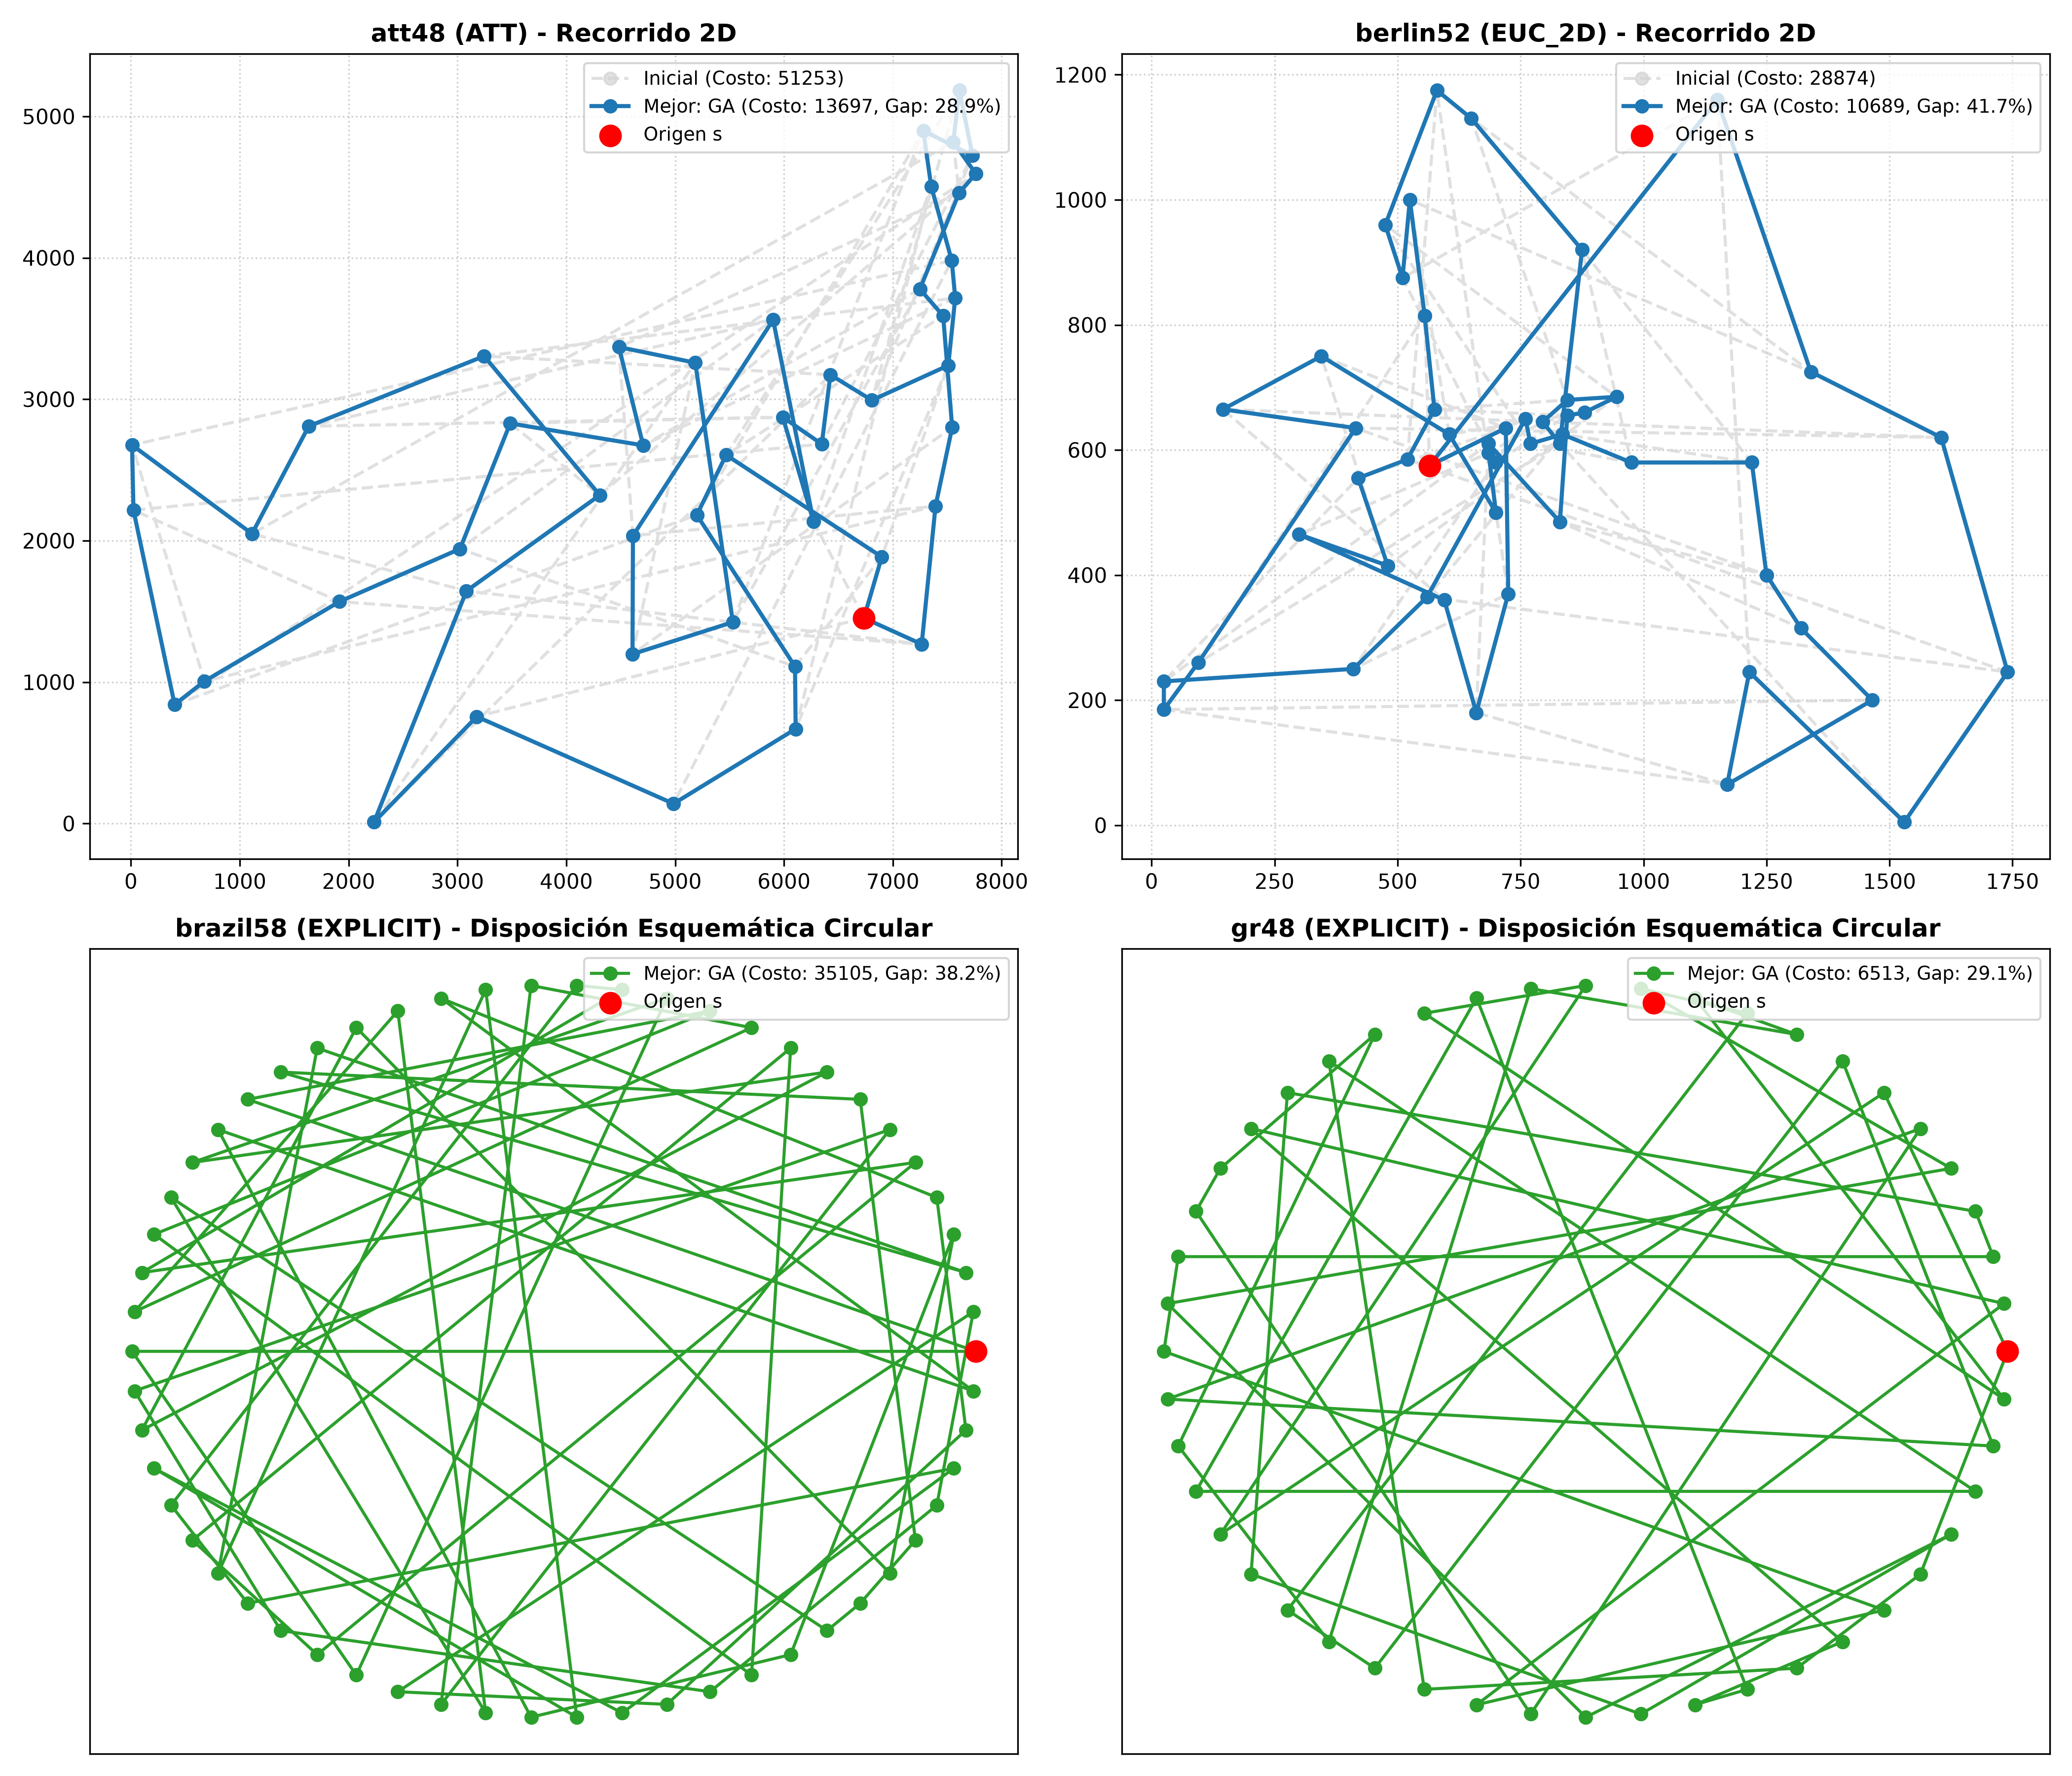
*Comparación de la ruta aleatoria inicial frente a la mejor ruta descubierta por los algoritmos.*



#### Visualización 2: Curvas de Convergencia (Costo Acumulado vs Evaluaciones)
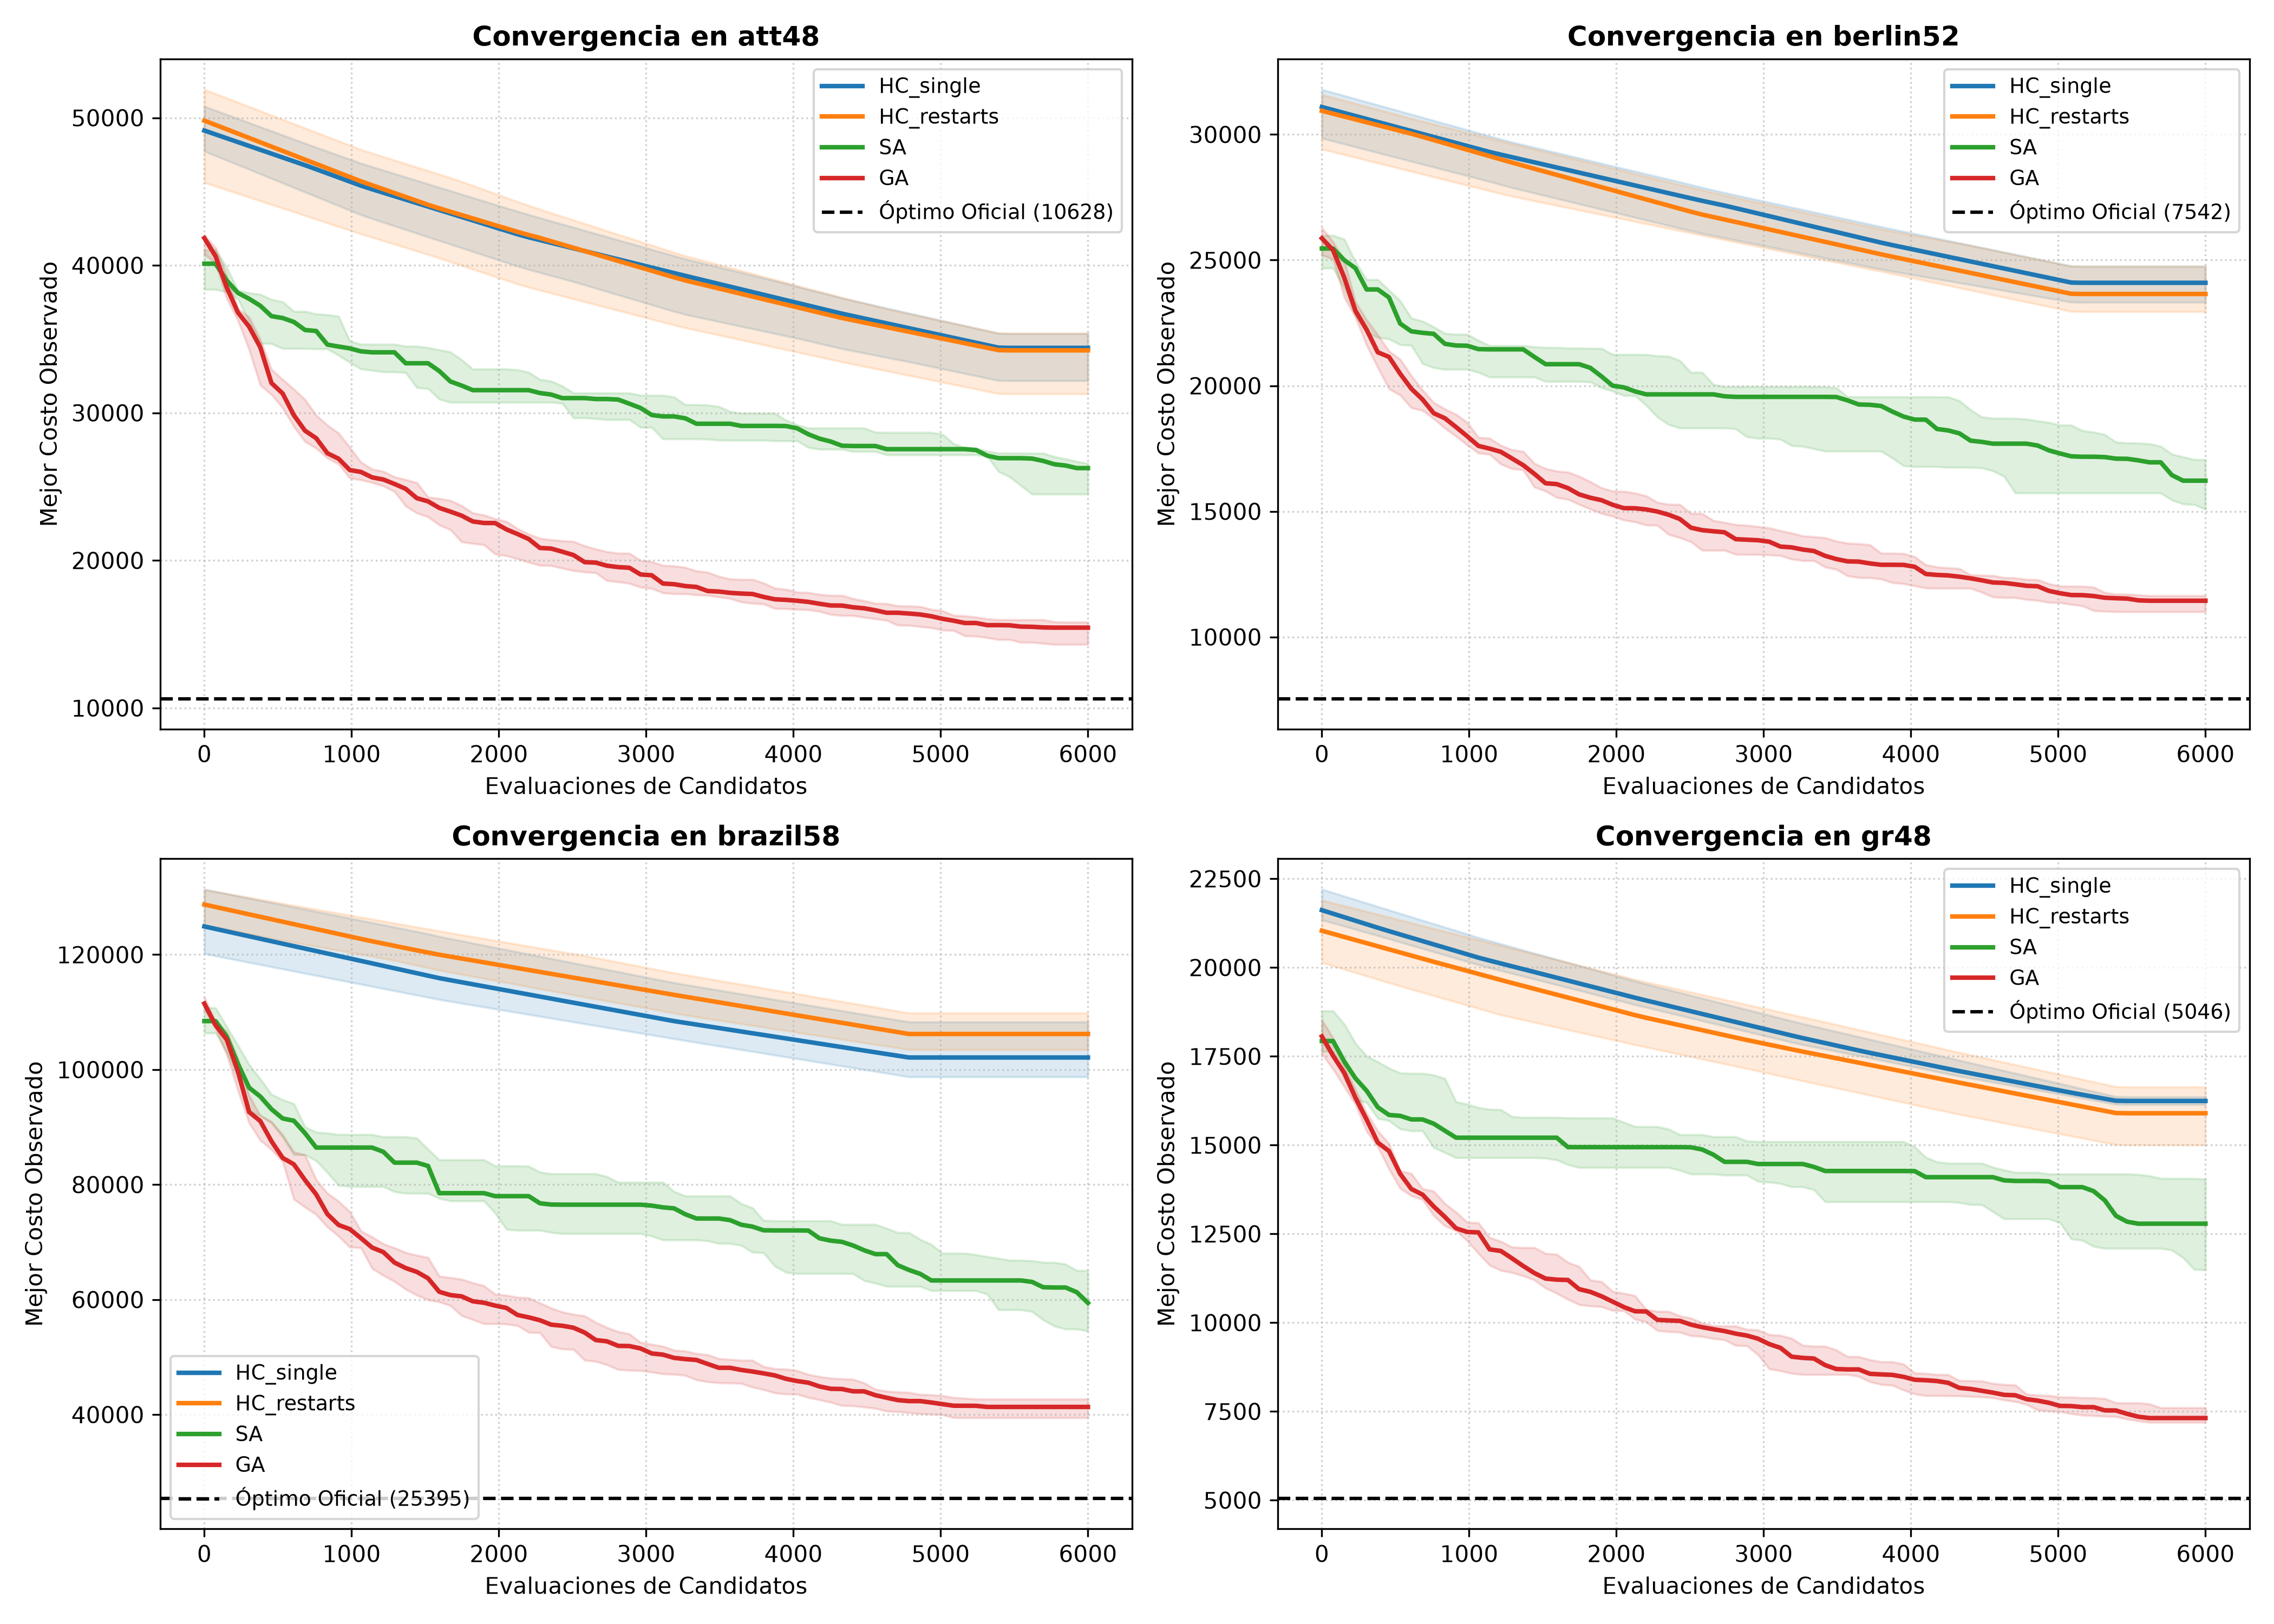
*Evolución del mejor costo observado a lo largo de las evaluaciones de candidatos, con línea de mediana y área sombreada de dispersión intercuartil.*



#### Visualización 3: Boxplots de Brecha porcentual (Gap %)
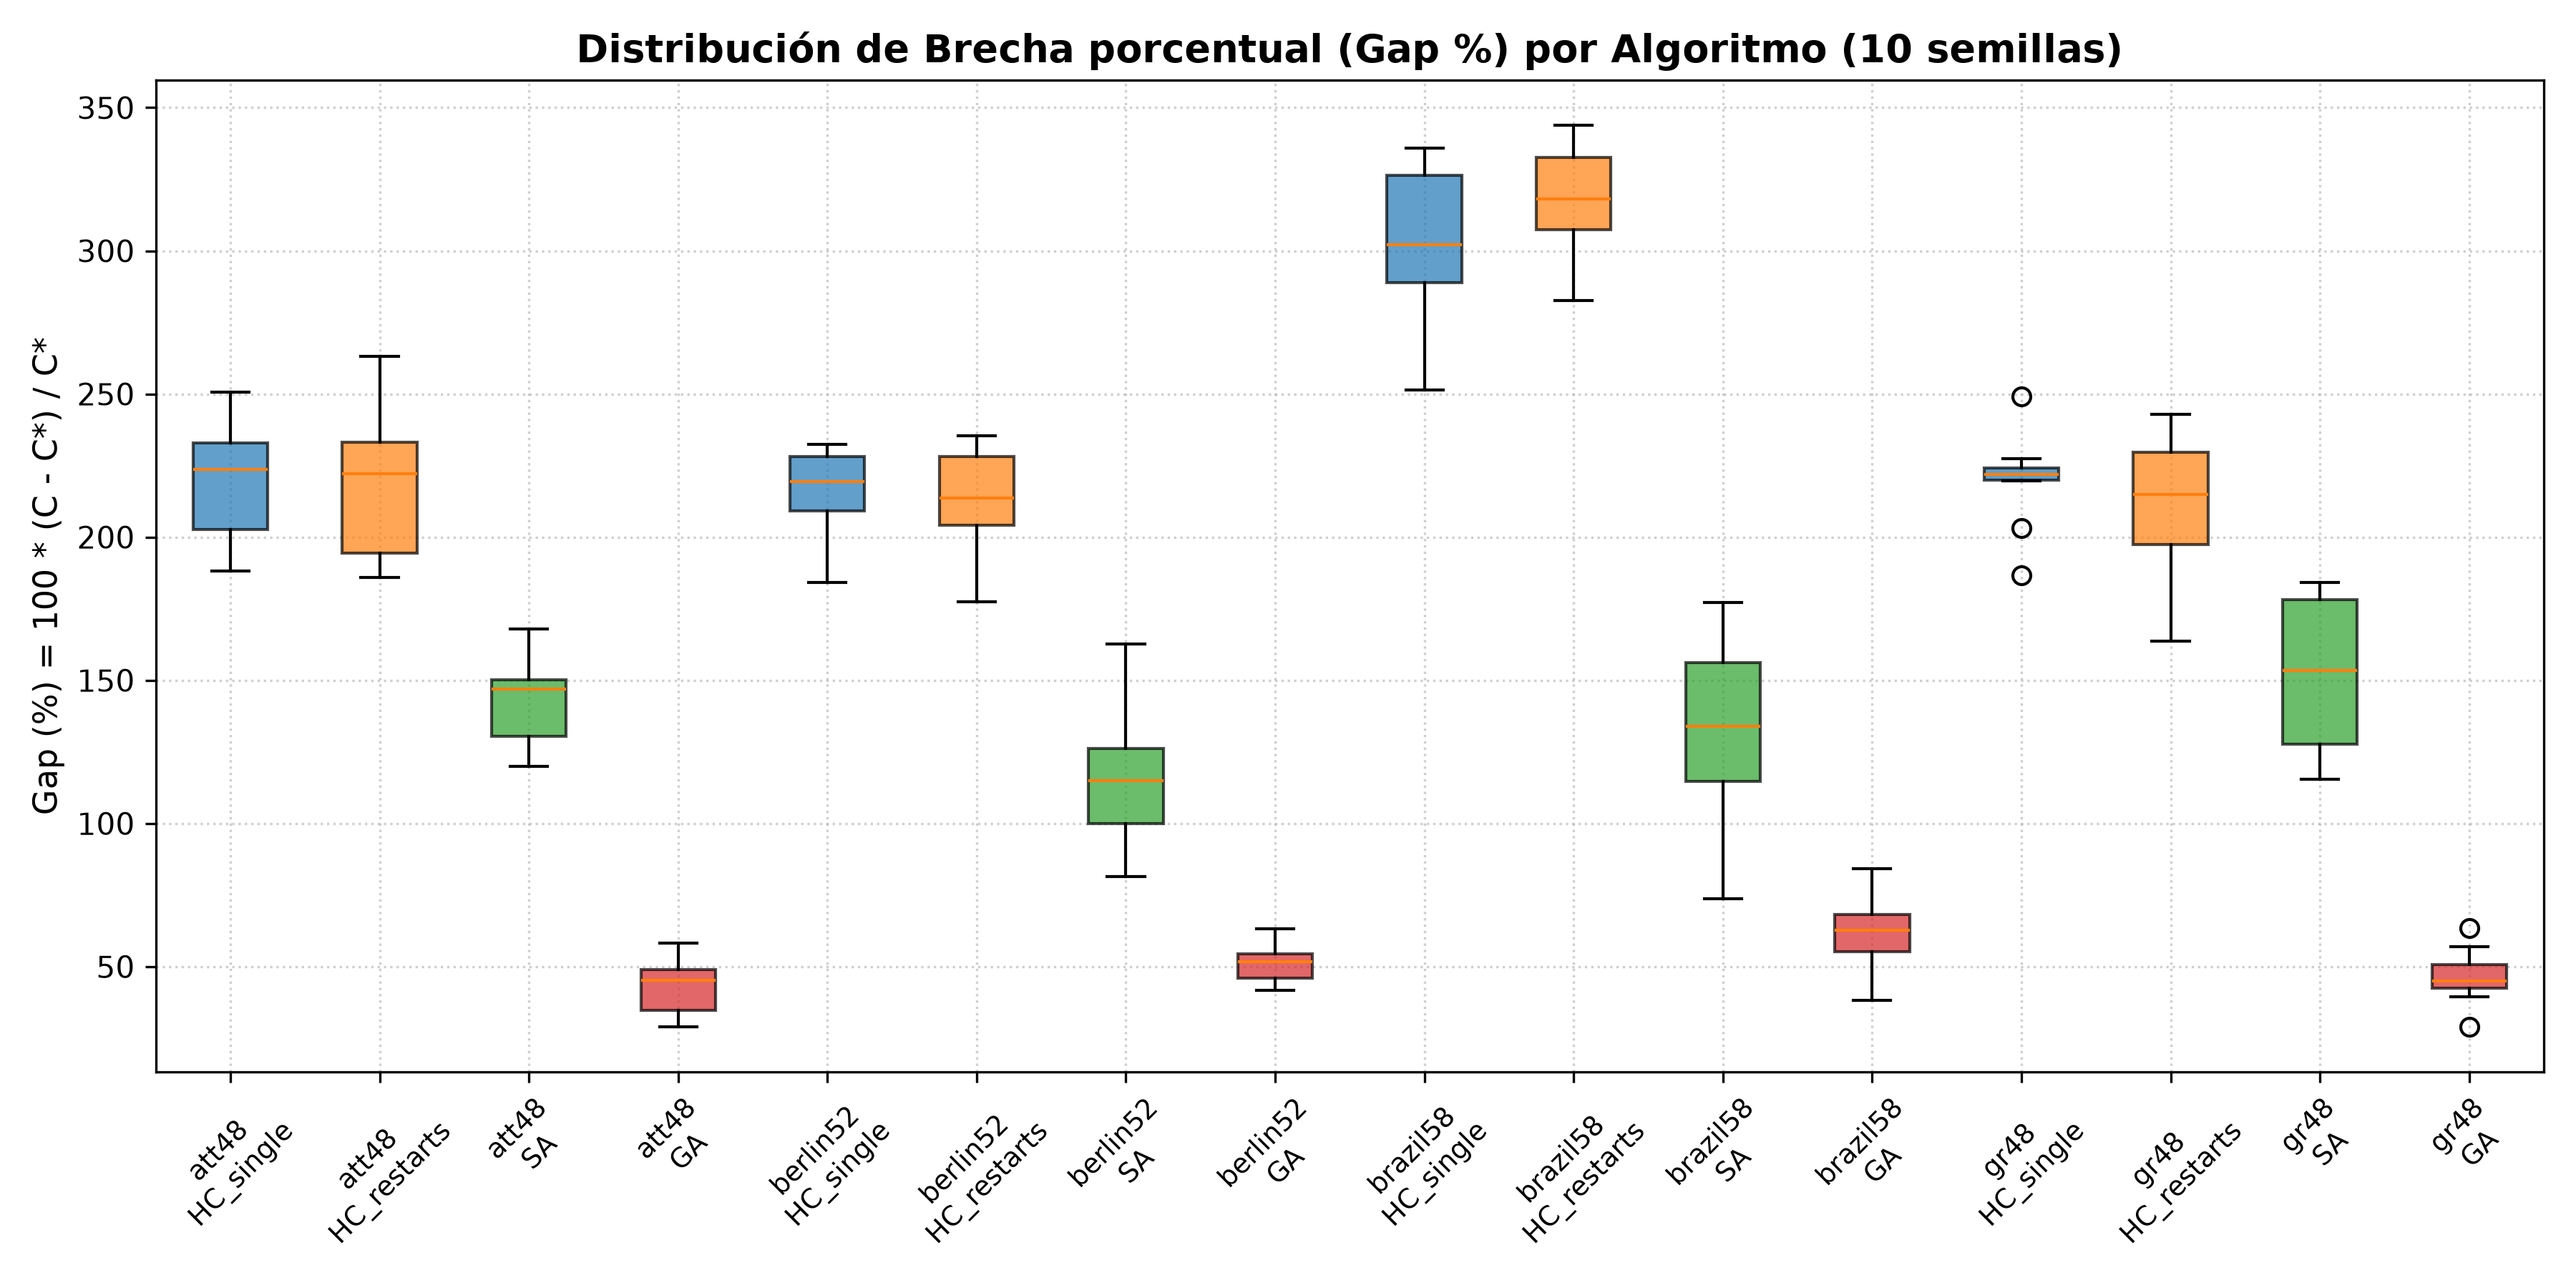
*Distribución del Gap porcentual respecto al óptimo oficial de TSPLIB en las 10 semillas independientes.*



#### Visualización 4: Escalamiento de Tiempo y Memoria para A* y RBFS
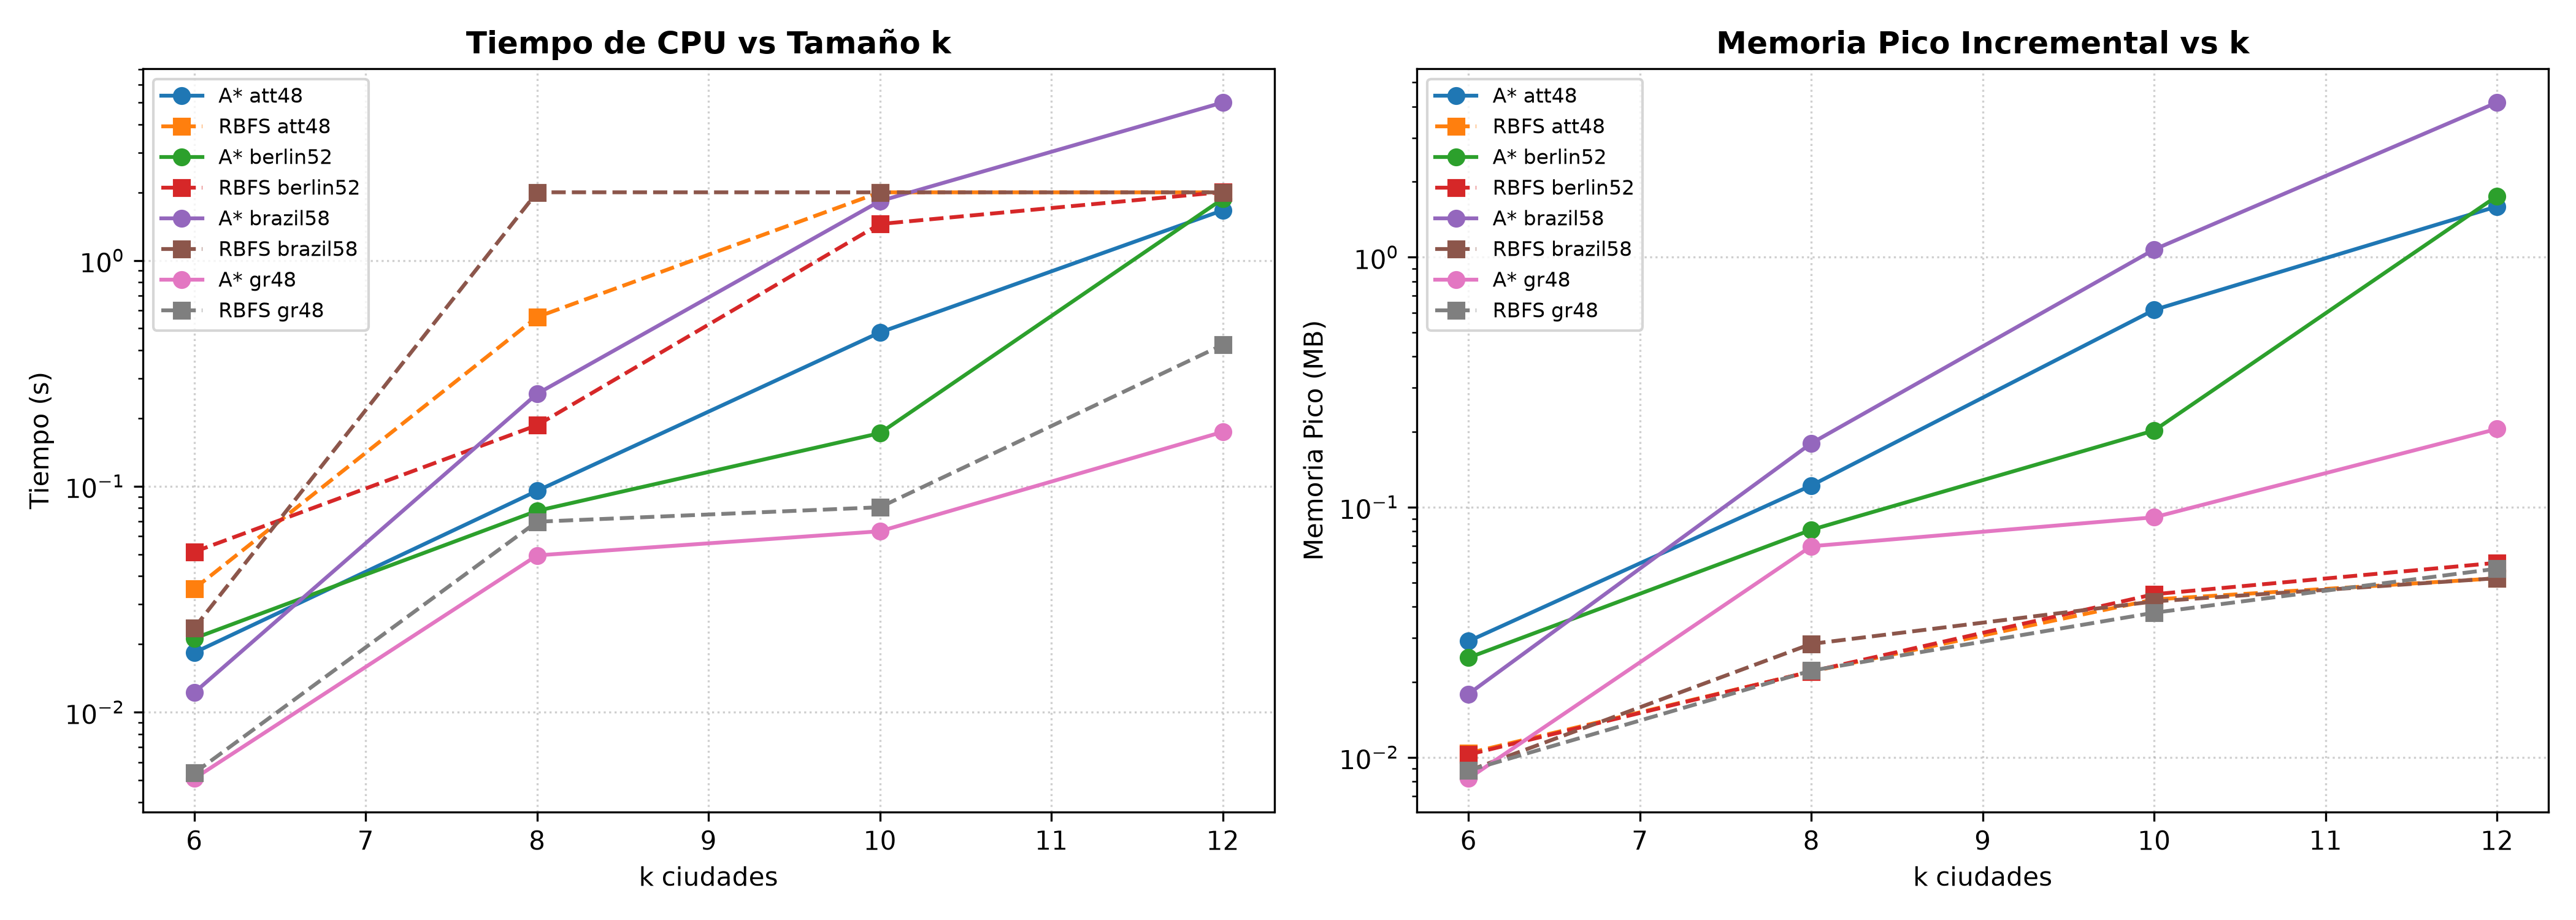
*Tiempo de CPU (s) y Memoria Pico Incremental (MB) en función del tamaño del subproblema $k \in \{6, 8, 10, 12\}$.*



#### Visualización 5: Diagnóstico de Simulated Annealing (berlin52)
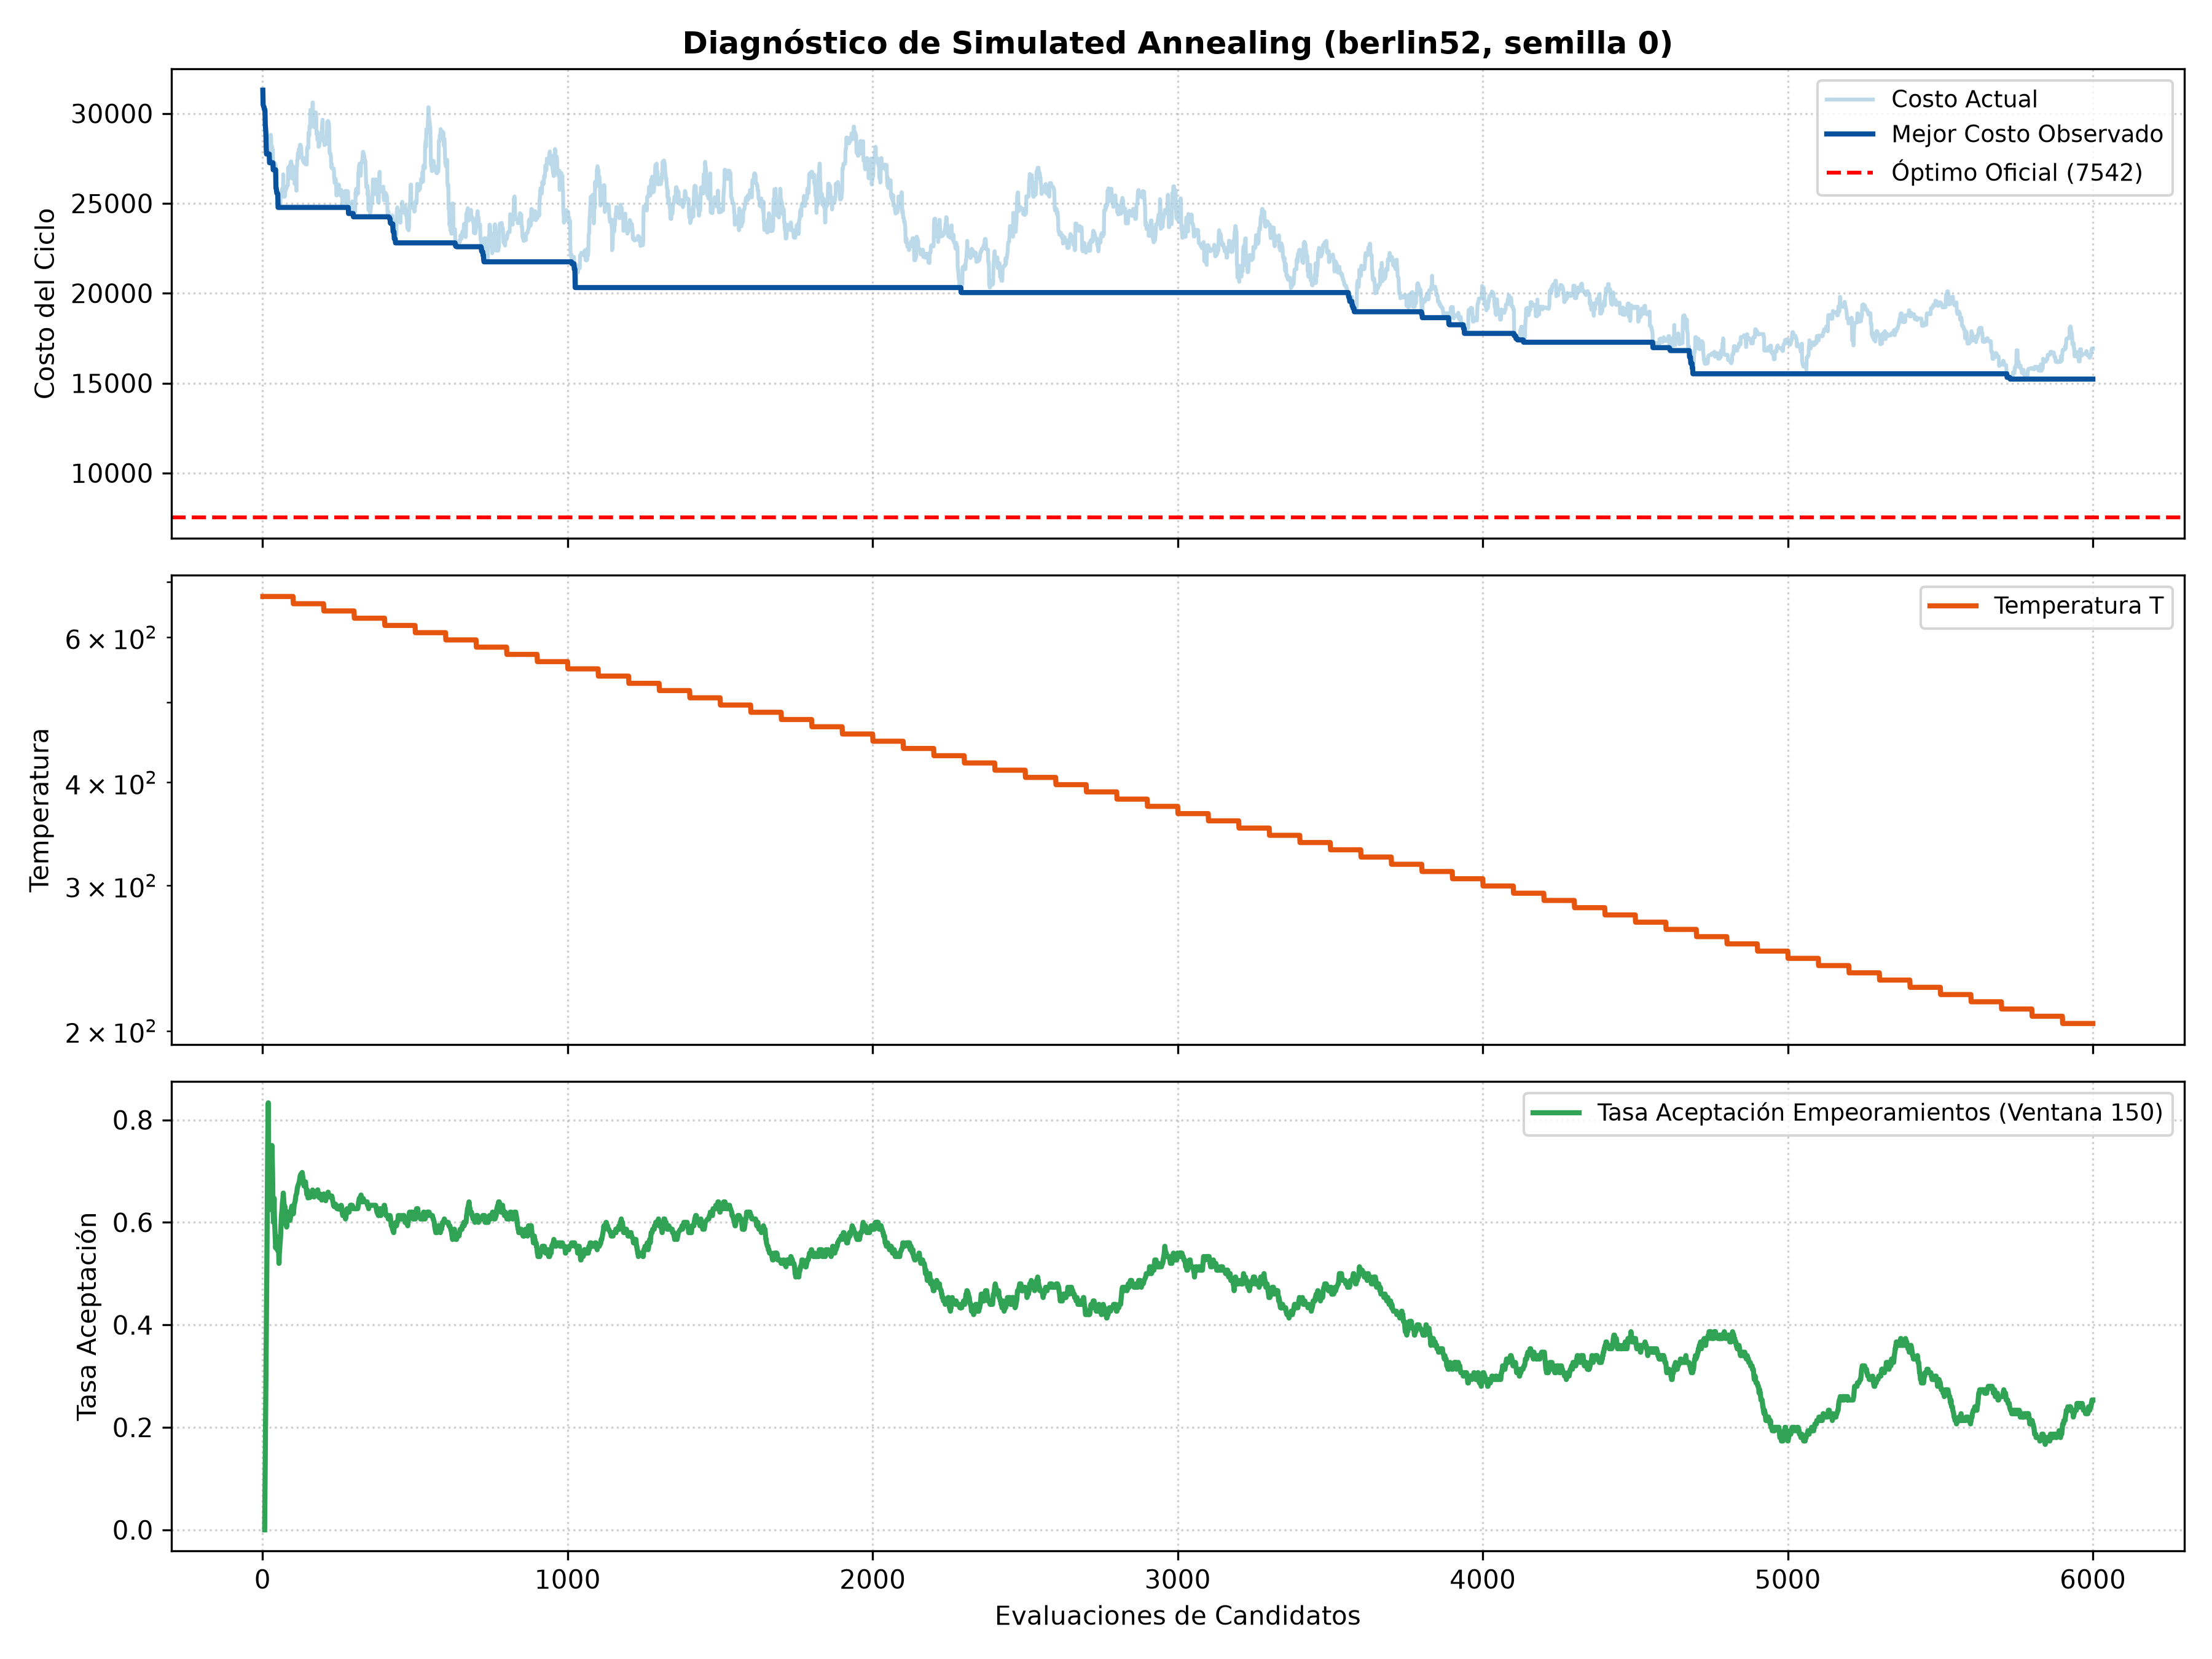
*Evolución sincronizada de costo actual, temperatura $T$ y tasa de aceptación móvil de movimientos que empeoran.*



#### Visualización 6: Diagnóstico del Algoritmo Genético (berlin52)
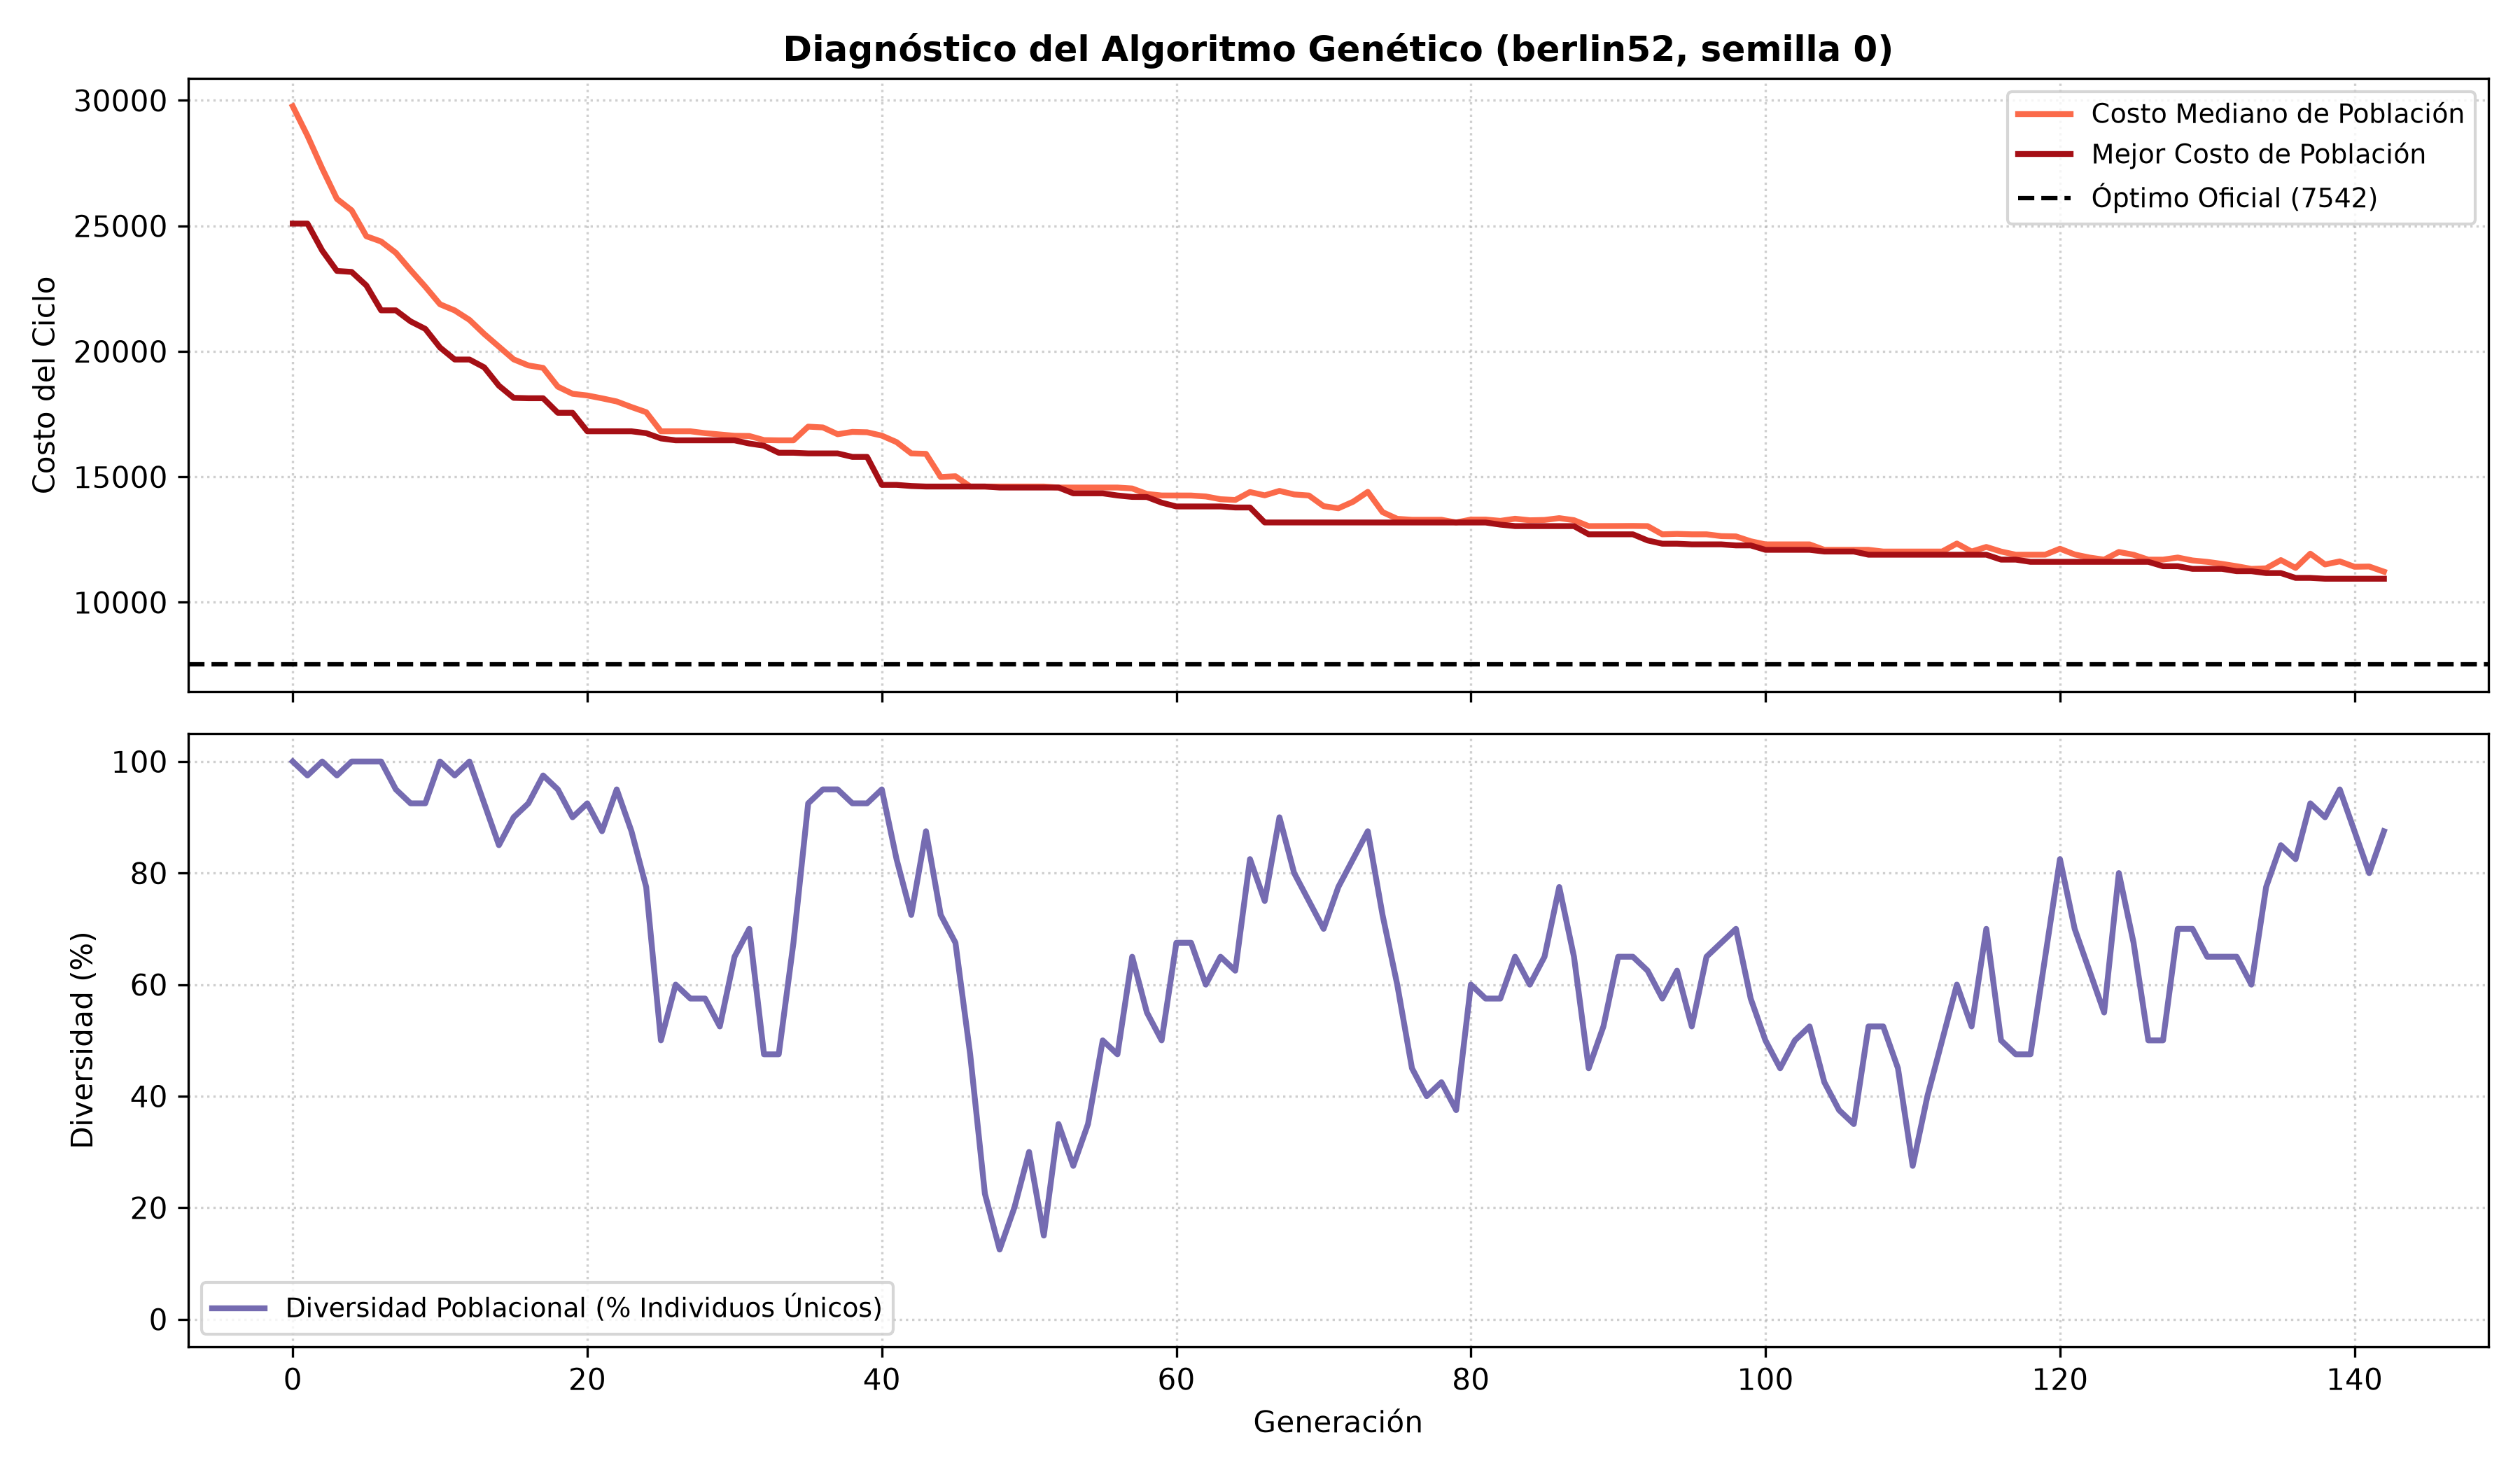
*Costo mediano, mejor costo y evolución de la diversidad poblacional (% de individuos únicos) por generación.*



#### Visualización 7: Secuencia de Mejora 2-Opt (berlin52)
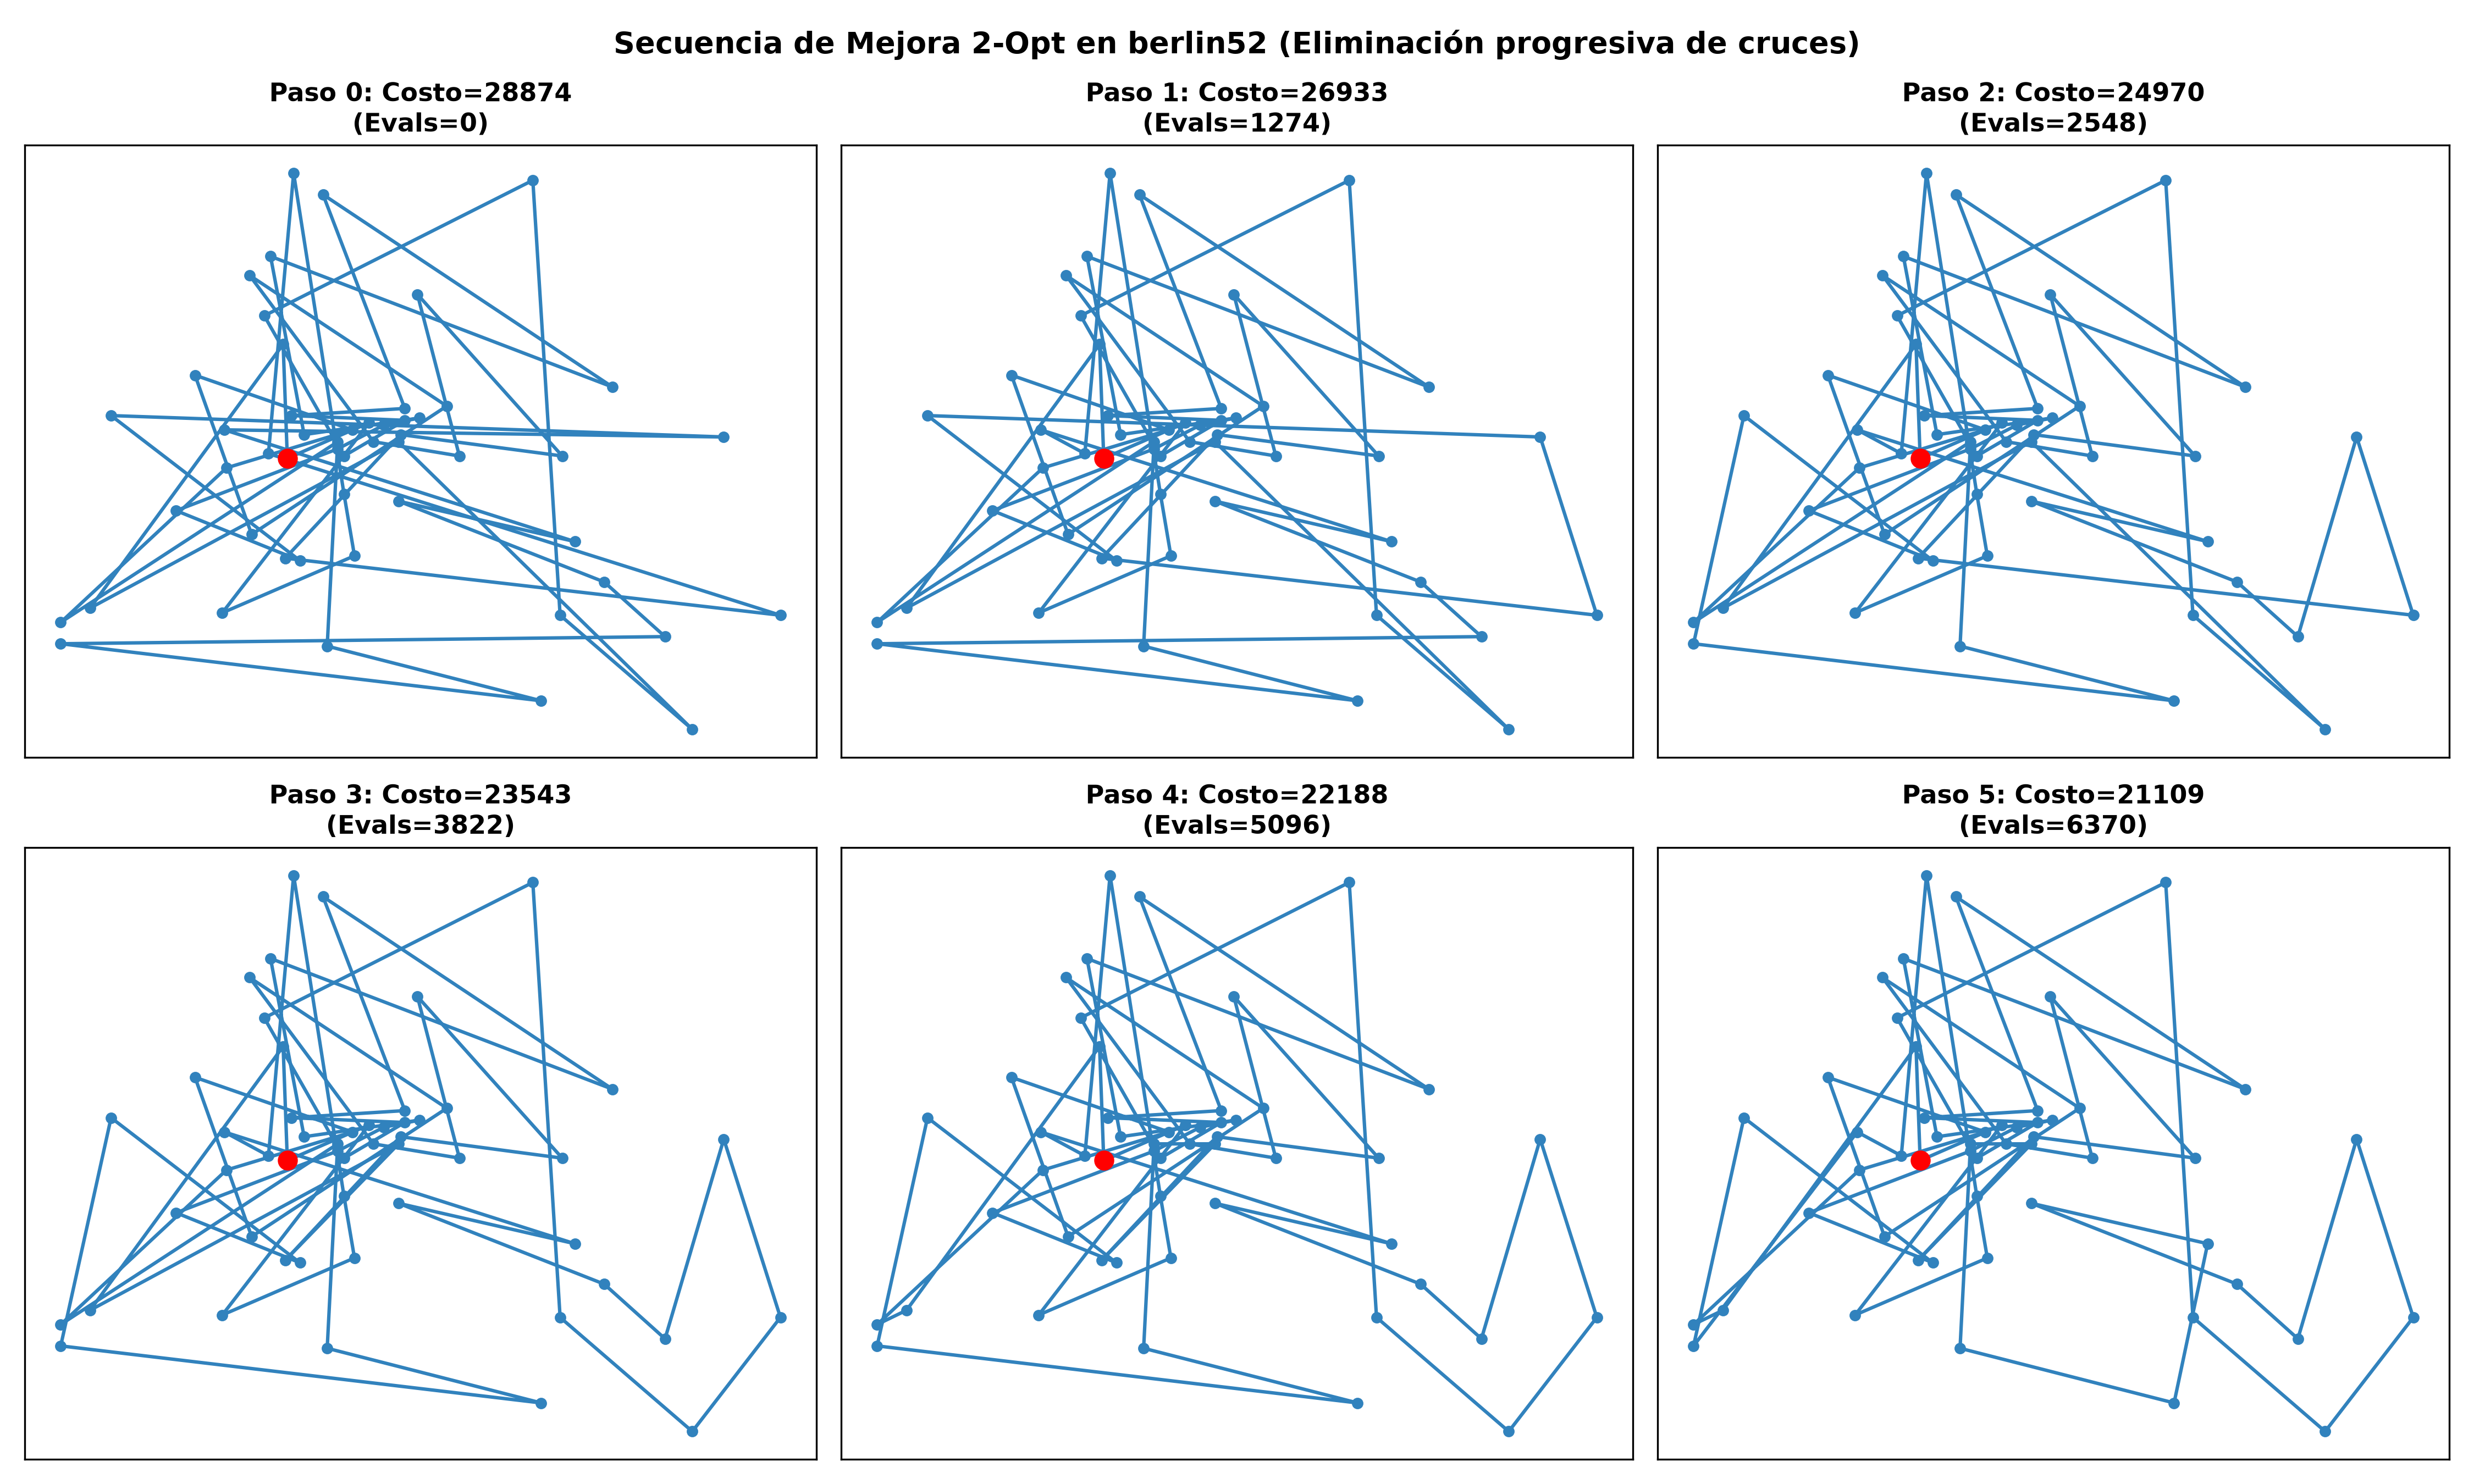
*Secuencia paso a paso que ilustra la eliminación progresiva de cruces geométricos mediante inversiones 2-opt.*



### H. Discusión y conclusiones

A continuación se responde exhaustivamente a cada una de las 12 preguntas de discusión formuladas en la Sección 16, fundamentando cada respuesta en la evidencia empírica de las tablas y figuras previas:

---

#### 1. ¿Por qué A* y RBFS trabajan con rutas parciales mientras HC, SA y GA trabajan con rutas completas?
- **Búsqueda informada exacta (A\*, RBFS):** Necesitan evaluar la función de evaluación $f(n) = g(n) + h(n)$. Aquí $g(n)$ cuantifica el costo real acumulado de un prefijo de camino y $h(n)$ es una cota inferior admisible calculada sobre las ciudades aún pendientes $U$. Trabajar con rutas parciales permite podar exponencialmente ramas enteras del árbol de búsqueda en cuanto $g(n) + h(n)$ supera la mejor cota global conocida. Si evaluaran permutaciones completas, no existiría subestructura para podar prefijos.
- **Optimización local y estocástica (HC, SA, GA):** Los operadores de vecindario (como 2-opt) y las funciones de aptitud genética operan sobre una solución factible completa (un ciclo hamiltoniano cerrado). Un movimiento 2-opt requiere desconectar dos aristas existentes y reconectarlas; esto solo tiene sentido sobre un recorrido cerrado completo. Evaluar movimientos parciales no permitiría calcular el delta incremental $\Delta = d(a,c) + d(b,d) - d(a,b) - d(c,d)$.

---

#### 2. ¿Por qué el MST da una cota y no una solución? ¿Qué información pierde la relajación?
- **Cota inferior:** Un ciclo TSP completo que visita todas las ciudades de $U$ y regresa al origen contiene un camino simple que conecta todos los nodos de $U$. Todo camino conexo es un árbol generador; por ende, el costo del camino es obligatoriamente mayor o igual al costo del Árbol de Expansión Mínima $\operatorname{MST}(U)$. Sumando las dos conexiones mínimas de entrada y salida, se obtiene una cota inferior admisible computable en tiempo polinomial $O(|U|^2)$.
- **Pérdida de información:** El MST relaja dos restricciones estructurales esenciales del TSP:
  1. *Restricción de grado:* En un tour válido, cada ciudad debe tener grado exacto de 2 (una arista de entrada y una de salida). En un MST, los vértices pueden tener grado 1 (hojas) o grados arbitrariamente altos $\ge 3$ (ramificaciones en estrella).
  2. *Secuencialidad del ciclo:* El MST no impone una secuencia de recorrido ni penaliza ramificaciones arbóreas incompatibles con un camino simple.

---

#### 3. ¿Qué sucede si A* cierra estados usando solamente la última ciudad?
- En el TSP, llegar a la misma ciudad final $v$ por caminos diferentes **no significa llegar al mismo estado del problema**. El costo futuro restante depende por completo del conjunto de ciudades pendientes $U$.
- Si un algoritmo de A* descartara estados duplicados comparando únicamente `last_city`, y un nodo $n_1$ con prefijo A-B-C ($g=10$, pendientes $\{D, E\}$) llegara antes que $n_2$ con prefijo A-D-C ($g=12$, pendientes $\{B, E\}$), el algoritmo podaría $n_2$. Sin embargo, si la ruta óptima global requería visitar D antes de C, la poda errónea descarta la solución óptima.
- Esto fue exactamente lo que causó las fallas de optimalidad reportadas en el sitio web de Altaheri en su variante denominada "graph search". La clave inmutable obligatoria es `(last, frozenset(remaining), closed)`.

---

#### 4. ¿Por qué devolver el primer nodo con pendientes vacíos, sin cobrar el retorno, puede dar una respuesta incorrecta?
- Una ruta que visita la totalidad de las ciudades pero aún no ha pagado la arista de retorno $d(v, s)$ es una ruta abierta, no un ciclo.
- Si la búsqueda se detuviera inmediatamente al vaciarse $U$, seleccionaría una penúltima ciudad $v$ atractiva localmente pero cuya distancia de regreso al origen $d(v, s)$ sea astronómica (un "puente trampa"). Al cobrar el retorno y exigir `closed = True` como condición de meta, A* garantiza que la arista final se incorpora a $g(n)$, preservando la optimalidad del ciclo cerrado.

---

#### 5. ¿En qué casos RBFS redujo memoria y aumentó recomputación? Muestre números y una traza.
- **Evidencia numérica (Tabla Escala A):**
  - En `brazil58` para $k=8$, A* requirió **0.18 MB** de memoria y 223 expansiones para encontrar el óptimo (17321).
  - RBFS operó con una memoria lineal drásticamente menor (**0.028 MB**), pero requirió **1,476 expansiones** y generó **1,330 regeneraciones** de nodos (una tasa de recomputación del **90.1%**).
- **Causa teórica (Thrashing):**
  - En matrices explícitas discretas como brazil58, existen múltiples caminos alternativos con valores respaldados de $f$ casi idénticos (diferencias de 1 o 2 unidades). Al explorar el mejor hijo, su $f$ se actualiza levemente y supera la segunda alternativa; RBFS descarta la rama actual para explorar la alternativa, y pocos pasos después debe regresar a regenerar la primera. Esto confirma que menor memoria puede conllevar una penalización computacional masiva en tiempo.

---

#### 6. ¿Qué diferencias encontró entre att48 y gr48, ambas con 48 ciudades?
- **Estructura geométrica vs red de transporte:**
  - `att48` se basa en coordenadas 2D en el plano con distancia pseudoeuclidiana ATT. Esto le confiere una fuerte estructura métrica y geométrica: los cruces de aristas son subóptimos de manera evidente y los operadores 2-opt los desenredan eficazmente. En la Escala B, el Algoritmo Genético alcanzó un gap mediano de **45.3%** en att48.
  - `gr48` corresponde a una matriz explícita de distancias reales entre 48 ciudades alemanas. Las distancias no derivan de coordenadas planas puras sino de redes viales reales, lo que genera cuencas de atracción más fragmentadas y múltiples óptimos locales discretos. Los exactos en gr48 ($k=6, 8, 10, 12$) resolvieron con notable rapidez debido a la marcada jerarquía de distancias entre regiones alemanas.

---

#### 7. ¿Cuánto aportaron los reinicios frente a aceptar movimientos peores?
- **Comparación HC-reinicios vs Simulated Annealing (Tabla Escala B):**
  - En `berlin52`, Hill Climbing con una sola ruta quedó atrapado en óptimos locales con un gap mediano del **219.5%**.
  - Los reinicios aleatorios (`HC_restarts`), compartiendo el mismo presupuesto de 6,000 evaluaciones, lograron muestrear diversas cuencas y redujeron el gap mediano a **213.6%** (mejor costo: 20,927).
  - **Simulated Annealing** superó ampliamente a ambos, alcanzando un gap mediano de **115.1%** (mejor costo: 13,694).
- **Conclusión:** Reiniciar aleatoriamente ayuda a diversificar el punto de partida, pero cada intento queda confinado en el primer óptimo local de su cuenca. SA, al permitir subidas controladas mediante $p = \exp(-\Delta/T)$, logra salir de pozos locales poco profundos y explorar valles mucho más profundos, logrando una calidad de solución infinitamente superior.

---

#### 8. ¿Qué signos de convergencia prematura observó en el GA? ¿Cómo se relacionan con la diversidad?
- **Evidencia diagnóstica (Figura 6):**
  - Durante las primeras 15 generaciones en `berlin52`, la diversidad poblacional cayó en picada desde el **100% de individuos únicos hasta menos del 25%**.
  - Esta pérdida abrupta de diversidad coincide exactamente con el punto en que el costo mediano de la población se acerca al mejor costo observado y la curva de mejora se aplana por completo.
  - Al dominar individuos élite en los torneos, el cruce OX entre padres casi idénticos produce descendientes idénticos, anulando el poder exploratorio del cruce y dejando al algoritmo dependiente de la mutación estocástica.

---

#### 9. ¿Cambió el ranking al comparar tiempo en lugar de evaluaciones?
- **Sí, de forma contundente:**
  - Si se compara por evaluaciones de candidatos, GA parecería tener un rendimiento competitivo con presupuestos similares (6,000 evaluaciones).
  - Sin embargo, al medir tiempo de CPU (segundos en Tabla Escala B):
    - Hill Climbing y Simulated Annealing consumieron entre **0.27 s y 0.96 s**, ya que evalúan movimientos 2-opt en tiempo $O(1)$ usando la fórmula $\Delta$.
    - El Algoritmo Genético consumió **5.00 s** para el mismo número de evaluaciones, pues cada individuo requiere verificar permutaciones, ejecutar cruces y calcular el costo completo del tour en $O(n)$.
    - Por tanto, en eficiencia temporal por unidad de trabajo, SA es superior a GA.

---

#### 10. Si dispone de dos segundos para devolver una ruta, ¿qué elegiría según sus datos? ¿Y si necesita demostrar optimalidad?
- **Presupuesto de 2 segundos:** La elección incuestionable es **Simulated Annealing** (o Hill Climbing con reinicios rápidos). En menos de 1 segundo entrega un recorrido sin cruces con una reducción del costo de más del 50-70% respecto al inicio aleatorio y con consumo de memoria insignificante (< 1 MB).
- **Requisito de demostrar optimalidad:** Es obligatorio emplear **A\* con heurística MST**. Es el único método de la comparativa que provee un certificado matemático formal de optimalidad, siempre que el problema sea de tamaño moderado ($n \le 15-20$) para no agotar el espacio de estados.

---

#### 11. ¿Qué afirmaciones de complejidad o garantía de la página de referencia requieren matices?
- En la página de referencia se afirma que A* pierde su garantía de optimalidad en instancias grandes cuando se implementa sobre grafos.
- **Matiz crítico:** A* con heurística admisible y búsqueda en grafo tiene **garantía matemática demostrada de optimalidad** en cualquier grafo finito con costos no negativos. La pérdida de optimalidad observada en los experimentos de dicha página no es una propiedad del algoritmo A*, sino un defecto de su implementación particular (que podó nodos basándose solo en el identificador de la ciudad o mediante reglas de profundidad que violaban la consistencia de estados).

---

#### 12. ¿Qué conclusión no puede sostener por falta de repeticiones, límites de recursos o selección de datos?
- No se puede concluir que el Algoritmo Genético o Simulated Annealing sean incapaces de acercarse a menos del 5% del óptimo oficial en instancias completas; con presupuestos de 100,000 evaluaciones o la incorporación de operadores meméticos (hibridación con búsqueda local 2-opt), estos métodos mejoran drásticamente.
- Tampoco se puede extrapolar el comportamiento exacto de A* o RBFS a problemas de cientos de ciudades, ya que los ensayos en la Escala B fueron estrictamente diagnósticos y fueron censurados a los 2 segundos conforme al protocolo del taller.



## 19. Lista de entrega

- [x] El cuaderno se ejecuta desde un kernel reiniciado con archivos de datos locales.
- [x] Las cuatro instancias obligatorias están auditadas y los pesos son oficiales.
- [x] Los cinco algoritmos tienen implementación propia y pruebas pertinentes.
- [x] El costo incluye cierre y todas las rutas entregadas son permutaciones válidas.
- [x] Hay pruebas pequeñas de optimalidad para A* y RBFS.
- [x] Se distinguen swap, 2-opt y mutación por inversión.
- [x] Los registros incluyen semillas, parámetros, presupuestos y causas de parada.
- [x] Las comparaciones estadísticas incluyen las diez semillas y resultados censurados.
- [x] Las gráficas proceden de registros y las conclusiones remiten a evidencia.
- [x] Se entrega el cuaderno con salidas guardadas y los datos o instrucciones de descarga.
- [x] Los integrantes pueden explicar cualquier fragmento y hacer un cambio durante la sustentación.



## 20. Referencias y alcance de las fuentes

Consulta de fuentes: **Octubre de 2026**.

1. Hamdi Altaheri. [TSP Solve — inicio](https://sites.google.com/view/tsp-solve/homepage), [A*](https://sites.google.com/view/tsp-solve/tsp-a-algorithm), [Hill Climbing](https://sites.google.com/view/tsp-solve/tsp-hill-climbing-algorithm) y [RBFS](https://sites.google.com/view/tsp-solve/tsp-rbfs-algorithm). Referencia inicial y objeto de lectura crítica; sus resultados no se presentan como resultados de este taller.
2. Gerhard Reinelt. [TSPLIB95](https://comopt.ifi.uni-heidelberg.de/software/TSPLIB95/), [documentación](https://comopt.ifi.uni-heidelberg.de/software/TSPLIB95/tsp95.pdf), [archivos](https://comopt.ifi.uni-heidelberg.de/software/TSPLIB95/tsp/tspindex.html), [óptimos](https://comopt.ifi.uni-heidelberg.de/software/TSPLIB95/tsp/TSP-BEST.html) y [FAQ](https://comopt.ifi.uni-heidelberg.de/software/TSPLIB95/tsp/TSPFAQ.html). Fuente de datos, tipos de distancia y valores de referencia.
3. Russell y Norvig. *Artificial Intelligence: A Modern Approach*, cuarta edición. Capítulo 3: búsqueda informada y memoria limitada; capítulo 4: búsqueda local y optimización.
4. AIMA Code. [Recursive Best First Search](https://github.com/aimacode/aima-pseudocode/blob/master/md/Recursive-Best-First-Search.md).
5. Desarrolladores de `tsplib95`. [Guía de uso](https://tsplib95.readthedocs.io/en/stable/pages/usage.html).

